<!--
SPDX-FileCopyrightText: Copyright (c) 2026 NVIDIA CORPORATION & AFFILIATES. All rights reserved.
SPDX-License-Identifier: Apache-2.0
-->

<div style="display:flex; align-items:center; justify-content:center; gap:22px; flex-wrap:wrap; width:100%; max-width:980px; margin:0 auto 16px; padding:10px 16px; box-sizing:border-box; background:#ffffff; border:1px solid #e5e7eb; border-radius:8px; box-shadow:0 1px 2px rgba(0,0,0,0.04);">
  <span style="display:flex; align-items:center; justify-content:center; flex:1.25 1 220px; min-width:180px; max-width:300px; height:76px;">
    <img src="assets/images/logos/nvidia-logo.png" alt="NVIDIA" style="display:block; max-width:100%; max-height:62px; width:auto; height:auto; object-fit:contain;">
  </span>
  <span style="display:flex; align-items:center; justify-content:center; flex:1 1 130px; min-width:110px; max-width:180px; height:58px;">
    <img src="assets/images/logos/eneos-orange.png" alt="ENEOS" style="display:block; max-width:100%; max-height:30px; width:auto; height:auto; object-fit:contain;">
  </span>
  <span style="display:flex; align-items:center; justify-content:center; flex:1.45 1 260px; min-width:220px; max-width:360px; height:86px;">
    <img src="assets/images/logos/matlantis.png" alt="Matlantis" style="display:block; max-width:100%; max-height:82px; width:auto; height:auto; object-fit:contain;">
  </span>
  <span style="display:flex; align-items:center; justify-content:center; flex:1 1 120px; min-width:100px; max-width:160px; height:58px;">
    <img src="assets/images/logos/ovito_logo.png" alt="OVITO" style="display:block; max-width:100%; max-height:32px; width:auto; height:auto; object-fit:contain;">
  </span>
</div>

# Batched Atomistic Simulation with <span style="color:#76b900; font-weight:600;">NVIDIA ALCHEMI</span>

<p style="margin-top:0; color:#555; font-size:0.95em;">
Inspiration for this tutorial is drawn from a fruitful three-way collaboration between NVIDIA ALCHEMI, ENEOS, and Matlantis: NVIDIA ALCHEMI provides the accelerated tutorial/runtime layer integrated into the Matlantis computational platform; ENEOS leverages Matlantis to study production oxygen evolution reaction (OER) catalysis search across a million-candidate space. OVITO is used for structure inspection and rendering. The notebook below is a simplified adsorption tutorial inspired by that real production search.
</p>

🔗 **ALCHEMI resources:** [ALCHEMI hub](https://developer.nvidia.com/cuda/cuda-x-libraries/alchemi) · [Toolkit GitHub](https://github.com/NVIDIA/nvalchemi-toolkit) · [Toolkit-Ops GitHub](https://github.com/NVIDIA/nvalchemi-toolkit-ops)

📰 **ALCHEMI blogs:** [ALCHEMI discovery blog](https://developer.nvidia.com/blog/revolutionizing-ai-driven-material-discovery-using-nvidia-alchemi/) · [Toolkit intro blog](https://developer.nvidia.com/blog/building-custom-atomistic-simulation-workflows-for-chemistry-and-materials-science-with-nvidia-alchemi-toolkit/) · [Toolkit-Ops blog](https://developer.nvidia.com/blog/accelerating-ai-powered-chemistry-and-materials-science-simulations-with-nvidia-alchemi-toolkit-ops/)

![Adsorption at scale with NVIDIA ALCHEMI Toolkit](assets/images/banner.jpg)

<!-- **Runtime target:** ALCHEMI Toolkit on a CUDA GPU  
**Teaching path:** batched MLIP relaxation with explicit structure, energy, and validation checkpoints  
-->

*This tutorial uses adsorption configuration search as an example of a broader shift: batched, GPU-native atomistic simulation lets a researcher run throughput calculations on a single modern GPU and route better-ranked structures into production workflows or whatever downstream review or validation path the project requires.*

**What you will do**

1. Use a small H<sub>2</sub>O example to see how batching changes runtime.
2. Run a limited OC20Dense reproducibility and model-sanity check against released DFT trajectories.
3. Build chemically meaningful adsorption starting structures.
4. Relax, rank, visualize, and interpret the final adsorption geometries.

## Chemical discovery starts as a search problem

Chemical discovery begins with an enormous, almost limitless solution space. A research goal can branch across composition, molecular structure, crystal structure, environment, target property, and practical constraints such as cost, safety, synthesis route, or lifetime. The first step is therefore not to run a model; those come soon. It is to define a meaningful search space.

A useful computational workflow narrows that space in stages:

- **Frame the scientific question.** Decide what is being optimized or rationalized: stability, selectivity, conductivity, degradation, binding, diffusion, emission, or another property.
- **Apply chemical judgement.** Use known chemistry, physics, synthesis constraints, and domain knowledge (human or even agentic) to remove candidates that are irrelevant or impossible for the intended application.
<div style="margin:18px auto 20px; max-width:920px; text-align:center; font-family:Inter, Arial, sans-serif;">
  <div style="margin:0 auto 7px; width:100%; padding:12px 18px; box-sizing:border-box; border:2px solid #d1d5db; background:#f9fafb; color:#1f2937; border-radius:8px;">
    <div style="font-weight:700; font-size:1.02em;">Chemical solution space</div>
    <div style="font-size:0.9em;">composition, structure, environment, target property, practical constraints</div>
  </div>
  <div style="margin:0 auto 7px; width:88%; padding:11px 18px; box-sizing:border-box; border:1.5px solid #d1d5db; background:#ffffff; color:#1f2937; border-radius:8px;">
    <div style="font-weight:700;">Frame the scientific question</div>
    <div style="font-size:0.9em;">stability, selectivity, binding, diffusion, degradation, conductivity, emission</div>
  </div>
  <div style="margin:0 auto 7px; width:76%; padding:11px 18px; box-sizing:border-box; border:1.5px solid #d1d5db; background:#ffffff; color:#1f2937; border-radius:8px;">
    <div style="font-weight:700;">Apply chemical judgement</div>
    <div style="font-size:0.9em;">remove irrelevant, impossible, unsafe, or out-of-scope candidates</div>
  </div>
  <div style="margin:0 auto 7px; width:64%; padding:11px 18px; box-sizing:border-box; border:1.5px solid #d1d5db; background:#ffffff; color:#1f2937; border-radius:8px;">
    <div style="font-weight:700;">Define the candidate set</div>
    <div style="font-size:0.9em;">molecules, conformers, crystals, defects, interfaces, adsorption geometries</div>
  </div>
  <div style="margin:0 auto 7px; width:52%; padding:11px 18px; box-sizing:border-box; border:1.5px solid #d1d5db; background:#f9fafb; color:#1f2937; border-radius:8px;">
    <div style="font-weight:700;">Choose the evidence ladder</div>
    <div style="font-size:0.9em;">screening signal, validation path, metadata</div>
  </div>
  <div style="margin:0 auto 7px; width:42%; padding:11px 18px; box-sizing:border-box; border:2px solid #76b900; background:#edf7e2; color:#18230f; border-radius:8px;">
    <div style="font-weight:700;">Batched GPU evaluation</div>
    <div style="font-size:0.9em;">evaluate many plausible structures in one GPU workflow</div>
  </div>
  <div style="margin:0 auto; width:32%; min-width:250px; padding:11px 18px; box-sizing:border-box; border:2px solid #d1d5db; background:#f9fafb; color:#1f2937; border-radius:8px;">
    <div style="font-weight:700;">Ranked candidates</div>
    <div style="font-size:0.9em;">inspect, compare, and escalate the strongest cases</div>
  </div>
</div>

Even after this narrowing, the candidate set can still contain hundreds, thousands, or millions of structures. The practical bottleneck is no longer only the model; it is the ability to evaluate many reasonable structures without turning every idea into a separate campaign.

This is where batching changes the practical landscape. Instead of turning every exploratory idea into a separate calculation campaign, large sets of MLIP relaxations can now run as throughput calculations on a single modern GPU.

Surface adsorption gives this general search problem a concrete shape. Once a molecule-on-surface question is selected, the workflow still has to choose the slab model: composition, Miller index, termination, supercell, coverage, frozen-layer convention, and surface preparation. Only then does the local configuration search begin: adsorption sites, molecular orientation, height, and sometimes multiple starting geometries for the same chemical idea. Adsorption is part of many real discovery pipelines: catalysis, separations, water harvesting, OER materials, framework materials, and surface chemistry. ALCHEMI enters at this point to help researchers navigate solution spaces of interest with GPU-native batched workflows.


## Where NVIDIA ALCHEMI fits

[<span style="color:#76b900; font-weight:600;">NVIDIA ALCHEMI</span>](https://developer.nvidia.com/cuda/cuda-x-libraries/alchemi) - the AI Lab for Chemistry and Materials Innovation - is built around a clear mission: accelerate chemical and materials discovery with AI. In practice, ALCHEMI brings together delivery modes such as domain-specific [NIM microservices](https://docs.nvidia.com/nim/alchemi/alchemi-bgr/latest/index.html), [ALCHEMI Toolkit](https://nvidia.github.io/nvalchemi-toolkit/) building blocks, and [Toolkit-Ops](https://nvidia.github.io/nvalchemi-toolkit-ops/) kernels for AI-enabled atomistic simulation. This tutorial focuses on the direct Toolkit path: use familiar Python structure tools, convert structures into Toolkit data objects, and run batched GPU geometry relaxations that are easy to inspect and extend.

ALCHEMI provides Toolkit data structures, optimizers, simulation components, and GPU kernels that can connect to familiar, established structure pipelines. In this notebook, the practical value is **batched**, **customizable**, **GPU-native** execution: familiar structure objects in, batched relaxation and simulation out.

The ALCHEMI pieces used in this tutorial are:

- <strong>Toolkit</strong> **Direct Python workflow.** This notebook uses the [ALCHEMI Toolkit API](https://nvidia.github.io/nvalchemi-toolkit/): build structures with ASE/pymatgen, convert them into `AtomicData`, pack them into a `Batch`, run a model and optimizer, then inspect the relaxed structures and metadata in Python.
- <strong>Toolkit-Ops</strong> **Accelerated operations under the hood.** [Toolkit-Ops](https://github.com/NVIDIA/nvalchemi-toolkit-ops) is the GPU-kernel layer for common batched atomistic operations such as neighbor lists, DFT-D3 dispersion corrections, and long-range electrostatics. The tutorial does not ask readers to call Toolkit-Ops directly, but it is part of the ALCHEMI stack that makes high-throughput simulation practical.
- **Pluggable MLIPs.** The runnable tutorial path uses MACE-MP/MACE-MPA checkpoints: `medium-mpa-0` for the main adsorption screen, with other open MACE-MP sizes used to compare throughput and memory use. Other MACE models, including MACE-MH-1 with an OC20 surface head, can be tested separately by changing the model setup and following the applicable upstream license. In other ALCHEMI workflows, the model can change with the chemistry while the batching, metadata, and verification pattern remains the same.

The discovery loop is the complete cycle: define a candidate set, generate valid structures with established tools, run batched GPU relaxations or simulations, rank reliable outputs, inspect failures, and decide which cases are ready for the next project-specific review step.

![ALCHEMI Toolkit and Toolkit-Ops architecture](assets/images/alchemi_toolkit_architecture.png)

## Tools at a glance

Before the code starts, here is the role of each scientific tool in this workflow. The stack is intentionally interoperable: use familiar structure tools, accelerate the bottleneck, and keep the outputs inspectable.

| Tool | What it does here |
|---|---|
| **NVIDIA GPU/CUDA** | Supplies the accelerated execution layer that makes many independent relaxations practical as a throughput calculation on one GPU. |
| **ALCHEMI Toolkit** | Connects atomistic structures to batched GPU execution, model wrappers, optimizers, constraints, and workflow metadata. |
| **FIRE2** | Geometry-optimization algorithm (*Fast Inertial Relaxation Engine*, version 2) provided by the Toolkit. It iteratively moves atoms downhill in energy until forces drop below a target threshold. |
| **MACE MLIPs** | Evaluate energies and forces for periodic slab and molecule calculations. The runnable adsorption screen uses open MACE checkpoints, with `medium-mpa-0` as the default and small-vs-large open MACE sizes used for the batch-size trade-off exercise. |
| **DFT** | *Density Functional Theory*: the quantum-chemistry reference method that MACE is compared against. The tutorial reports MACE results next to DFT-computed reference adsorption energies wherever available. |
| **D3(BJ)** | Grimme D3 dispersion correction with Becke-Johnson damping; a van der Waals add-on to DFT. Kept disabled in this tutorial to match the OC20 reference convention. |
| **AdsorbML-style search** | Provides the workflow pattern: generate many plausible adsorbate placements, relax them, rank the final structures, and inspect failures instead of trusting one initial guess. |
| **OC20Dense** | A densely sampled subset of the Open Catalyst 2020 dataset; provides DFT-relaxed structures and DFT-computed adsorption energies used for the closed-shell H2O/NH3/N2 accuracy validation in this tutorial. |
| **ASE** | Builds and stores atomistic structures in Python: gas molecules, slabs, adsorbate-slab starts, and relaxed outputs. |
| **pymatgen** | Builds crystal surfaces and terminations from bulk crystal structures, especially for oxide slabs where the surface model matters. |
| **OVITO** | Scientific molecular rendering platform. |


Surface adsorption makes the search problem easy to see. A molecule can approach the same surface through different atoms, different orientations, and different sites. Several starts may look chemically reasonable, but after relaxation they can settle into different local minima.

The 2023 AdsorbML study showed a practical shift for adsorption-energy workflows: instead of relaxing one manually chosen pose, generate many plausible adsorbate-surface configurations, use ML potentials to relax or filter them, and reserve higher-fidelity effort for the resulting shortlist. One balanced setting reported finding the lowest-energy configuration 87.36% of the time with about a 2000x speedup ([Lan et al., 2023](https://doi.org/10.1038/s41524-023-01121-5)).

This tutorial borrows that workflow logic. After the surface model is chosen, the calculation enumerates a local adsorption parameter space: candidate sites, orientations, heights, and related starting geometries. The goal is not to trust one plausible initial guess, but to search the defined configuration space and identify the lowest-energy relaxed structure found within it.

A batched search therefore asks a more useful question:

> **Given this surface model and adsorption parameter space, what is the best relaxed structure the workflow can find?**

ALCHEMI makes that search practical by running many independent starting structures as a batched GPU workflow, so the parameter sweep becomes part of the calculation rather than an informal manual preselection.

The same logic appears across many chemical domains. For adsorption it is sites and orientations. For molecules it may be conformers or protonation states. For materials it may be defects, terminations, dopants, interfaces, or local atomic arrangements. In catalysis, separations, water harvesting, OER frameworks, and surface chemistry, batching makes it practical to test many candidates instead of treating one starting structure as an invisible assumption.


## Roadmap: batching first, model check before screening

Batched relaxation only helps if the model is suitable for the chemistry being searched. Here that means an MLIP that has seen surface chemistry and can handle adsorbate-slab geometries well enough to support screening.

The notebook therefore builds the story in order: first make the Toolkit batching pattern concrete with a small H<sub>2</sub>O example, then check the selected open MACE path against released OC20Dense adsorption data, and only then use the same workflow for a broader adsorption search.

The opening workflow is:

- introduce the ALCHEMI Toolkit objects with a simple molecule batch;
- measure what batching changes computationally;
- check energy and relaxation behavior on known DFT trajectory data;
- generate a batched adsorption search for the systems we want to explore;
- relax, rank, and inspect the resulting geometries.

The validation checkpoint is part of the tutorial flow: the OC20Dense-backed cells use exact starting structures, DFT-relaxed final structures, DFT-level adsorption-energy targets, clean-slab references, gas references, MACE single-point energies, and Toolkit relaxations that can be audited from dataset-backed files.

The generated adsorption panel is a screening example. It shows how to build, relax, rank, and inspect many candidate geometries. Quantitative comparison to literature requires matched surface models, coverage, functional, dispersion treatment, constraints, and adsorption-energy convention.

---

## Run configuration

Edit the next cell to set how the notebook will run. Every section downstream reads the same `Config` object, so one edit here changes the whole workflow.

`Config` exposes two compute scopes:

- `RUN_SCOPE="short"` runs one representative adsorption example with six starting structures. Use it to check the workflow, kernel, GPU connection, and result tables quickly.
- `RUN_SCOPE="full"` runs the complete active adsorption grid defined in this notebook. Use it when you want the full site and orientation search for every adsorbate-surface example.

It also exposes two result sources, one for the tutorial section and one for the validation section:

- `"compute"` reruns the section and writes a new timestamped output folder.
- `"saved"` reads existing results, useful for browsing the tutorial without waiting for GPU work.

Leave `SAVED_TUTORIAL_RUN_ID` and `SAVED_ACCURACY_RUN_ID` as `None` unless you want to reopen a specific previous run. Pass `"latest-complete"` only when you want the newest live run that passes completeness checks.

Keep `REFRESH_SAVED_RESULTS=False` unless you are deliberately rebuilding the shipped saved results.

This version is Toolkit-only: relaxations run through the ALCHEMI Toolkit on the cluster GPU.

D3 is available in Toolkit workflows, but it is disabled here because the OC20Dense validation data follows the non-D3 OC20 convention. If you enable D3 for another dataset or application, record the explicit parameters in the run metadata.

`cfg.activate()` prints the resolved run summary and exports the legacy ALL_CAPS names (`RUN_SCOPE`, `TUTORIAL_OUTPUT_DIR`, ...) that later cells reference.

<div style="border-left:5px solid #cc7a00; background:#fdf6e3; padding:12px 16px; margin:12px 0; border-radius:6px; font-family:Inter, Arial, sans-serif;"><div style="font-weight:700; color:#cc7a00; margin-bottom:5px; font-size:0.9em; letter-spacing:0.03em; text-transform:uppercase;">⚙️ Acceleration & accuracy choices</div><div style="color:#1f2937; font-size:0.95em; line-height:1.5;"><code>TOOLKIT_DEVICE</code> — <code>auto</code> picks the GPU when present, else CPU; set <code>cuda</code> or <code>cpu</code> explicitly to compare. <code>TOOLKIT_COMPILE_MODEL</code> — <code>torch.compile</code> trades a slow first call for faster fixed-shape reruns; keep it off for quick or shape-varying interactive work. <code>TOOLKIT_ENABLE_CUEQ</code> — cuEquivariance kernels speed up the equivariant model on supported NVIDIA GPUs (CUDA only; ignored on CPU). D3(BJ) dispersion is available but left off here to match the non-D3 OC20Dense reference convention.</div></div>

<div style="border-left:5px solid #00a3e0; background:#eef7fb; padding:12px 16px; margin:12px 0; border-radius:6px; font-family:Inter, Arial, sans-serif;"><div style="font-weight:700; color:#00a3e0; margin-bottom:5px; font-size:0.9em; letter-spacing:0.03em; text-transform:uppercase;">ℹ️ What cfg.activate() injects</div><div style="color:#1f2937; font-size:0.95em; line-height:1.5;"><code>cfg.activate()</code> resolves the device, dtype, and output paths once and injects the names later cells use without re-importing: <code>toolkit_device</code>, <code>toolkit_dtype</code>, <code>tutorial_relpath</code>, <code>TUTORIAL_OUTPUT_DIR</code>, <code>LIVE_OUTPUT_DIR</code>, <code>CACHE_DIR</code>, <code>USE_SAVED_TUTORIAL_RESULTS</code>, <code>RUN_SCOPE_LABEL</code>, and the <code>RUN_SCOPE</code> / <code>*_RESULT_SOURCE</code> switches. When a later cell uses a bare name like <code>toolkit_device</code>, this is where it came from.</div></div>

In [1]:
from helpers.config import Config

cfg = Config(
    RUN_SCOPE="full",  # "short" (quick check) or "full" (complete grid)
    TUTORIAL_RESULT_SOURCE="compute",  # "compute" recomputes; "saved" reads the shipped cache
    VALIDATION_RESULT_SOURCE="compute",  # same switch for the accuracy section
    REFRESH_SAVED_RESULTS=False,  # True only when rebuilding the shipped cache
    REQUIRE_VISRTX_RENDER=False,  # True only on a workstation with VisRTX
    TOOLKIT_DEVICE="auto",  # "auto", "cuda", or "cpu"
    TOOLKIT_DTYPE="float32",  # "float32" or "float64"
    TOOLKIT_COMPILE_MODEL=False,  # torch.compile; adds compilations overhead but accelerates wokrflows - ENABLE in real simulations
    TOOLKIT_ENABLE_CUEQ=True,  # cuEquivariance kernels when the model supports them
    TOOLKIT_MATMUL_PRECISION="high",  # "high"/"highest"/"medium"; high enables TF32 matmul on NVIDIA GPUs
)
cfg.activate()

# torch.compile compatibility for MACE force autograd. This must be set
# before any compiled model is constructed in this kernel.
try:
    import torch._functorch.config  # noqa: F401

    torch._functorch.config.donated_buffer = False
except (ImportError, AttributeError):
    pass

RUN_SCOPE                         : full (full grid)
EXECUTION_PATH                    : toolkit
TUTORIAL_RESULT_SOURCE            : compute
VALIDATION_RESULT_SOURCE          : compute
REFRESH_SAVED_RESULTS             : False
SAVED_TUTORIAL_RUN_ID             : official
SAVED_ACCURACY_RUN_ID             : official
TUTORIAL_OUTPUT_DIR               : outputs/live_runs/20260617-064858/tutorial
ACCURACY_OUTPUT_DIR               : outputs/live_runs/20260617-064858/accuracy
CACHE_DIR                         : outputs/live_runs/20260617-064858/tutorial/cache_tables
SURFACE_SCREEN_OUTPUT_ROOT        : outputs/live_runs/20260617-064858/tutorial/surface_screen_v1_mace_mpa0_full/surface_screen
TOOLKIT_DEVICE                    : auto
TOOLKIT_DTYPE                     : float32
TOOLKIT_COMPILE_MODEL             : False
TOOLKIT_ENABLE_CUEQ               : True
TOOLKIT_MATMUL_PRECISION          : high
REQUIRE_VISRTX_RENDER             : False
--------------------------------------------------
pyth

In [2]:
# Library imports used across the notebook. Helpers that teach a concept are
# imported inline next to their first use; the imports below are utility surfaces
# (display widgets, plot builders, path helpers, table builders) where the
# audience does not need to think about internals.
import os
from pathlib import Path

import ase
import numpy as np
import pandas as pd
from ase.build import molecule as ase_molecule

from helpers import (
    # Result types and conversion
    Configuration,
    ase_to_atomic_data,
    atomic_data_to_ase,
    # D3 dispersion (paired with toolkit relaxation when applicable)
    ToolkitD3BJConfig,
    # Slab builders for the binary oxide and nitride facets; the construction
    # concept is taught with the Cu builders below at first use.
    build_tio2_110_slab,
    build_tio2_100_slab,
    build_tio2_101_slab,
    build_tin_001_slab,
    build_tin_110_slab,
    build_tin_210_slab,
    # Molecule builders for adsorbates and gas-phase references
    build_co,
    build_h2o,
    build_nh3,
    build_methanol,
    # Surface-screen specs and path / artifact utilities
    SurfaceScreenSlabSpec,
    SurfaceScreenAdsorbateSpec,
    surface_screen_expected_counts,
    surface_screen_plan_table,
    surface_screen_output_paths,
    require_surface_screen_artifact,
    safe_artifact_label,
    surface_screen_result_json_path,
    # Audit and summary tables
    audit_initial_configs,
    build_step_statistics,
    summarize_surface_screen_pairs,
    # Validation context table and result-presentation wrappers
    validation_context_table,
    show_trajectory_validation_results,
    show_nh3_ranking_results,
    validation_trajectory_artifact_paths,
    # Batch-size sweep helpers
    build_config_grid,
    load_or_run_adsorption_batch_sweep,
    display_adsorption_batch_sweep_results,
    # Result-analysis tables and heatmap
    build_application_heatmap,
    build_difficult_cases,
    # Visualization
    display_widgets_row,
    display_inline,
    NotebookProgress,
    plot_h2o_batch_speedup,
    plot_adsorption_batch_sweep,
    plot_device_throughput_comparison,
    plot_surface_screen_heatmap,
    # Presentation helpers: keep DataFrame styling and callouts out of code cells.
    styled_table,
    callout,
)

---

## Batched H<sub>2</sub>O relaxation: Molecular "Hello World" in Toolkit

Before building surfaces, start with a controlled molecule-only example: many independent water molecules, relaxed together through the Toolkit.

The chemistry is intentionally simple so the batching pattern is visible. The model is loaded once, the structures are packed into one `Batch`, and the GPU processes many small systems together instead of repeating the same setup one structure at a time.

### Toolkit basics: molecule -> batch -> relaxation

Start with the chemistry object and build up one layer at a time. In the next cells, H<sub>2</sub>O is deliberately simple so the Toolkit pattern is the part to focus on:

1. make one ASE `Atoms` molecule;
2. make a short list of independent ASE structures;
3. convert each structure to Toolkit `AtomicData`;
4. pack the list into one GPU `Batch`;
5. load a MACE model with `MACEWrapper`;
6. relax the whole batch with `FIRE2`.

Only after this explicit run do we wrap the same steps into a small timing function and plot the speedup. That keeps the science and the Toolkit steps visible before the benchmarking machinery appears.


<div style="border-left:5px solid #76b900; background:#f0f7e6; padding:12px 16px; margin:12px 0; border-radius:6px; font-family:Inter, Arial, sans-serif;"><div style="font-weight:700; color:#76b900; margin-bottom:5px; font-size:0.9em; letter-spacing:0.03em; text-transform:uppercase;">🧩 The ALCHEMI Toolkit object model</div><div style="color:#1f2937; font-size:0.95em; line-height:1.5;">ASE <code>Atoms</code> → <code>AtomicData</code> (one graph per structure) → <code>Batch.from_data_list(...)</code> (many graphs packed into one GPU object) → a model (<code>MACEWrapper</code>) plus an optimizer (<code>FIRE2</code>) → a relaxed <code>Batch</code>. Every section below reuses this same five-step path; only the structures and the model settings change.</div></div>

In [3]:
# Step 1: construct the molecule and a small list of independent inputs.
from time import perf_counter

H2O_EXAMPLE_BATCH_SIZE = 4

# ASE is the molecule-building layer. It returns an Atoms object with element
# identities and Cartesian coordinates. For this molecule-only API example we
# keep it non-periodic; surface cells and gas-reference boxes appear later.
h2o_single = ase_molecule("H2O")
h2o_single.info["structure_id"] = "H2O_single"

print(f"One ASE object: H2O | atoms={len(h2o_single)} | pbc={h2o_single.pbc.tolist()}")
display_widgets_row(
    [("one H2O molecule", h2o_single)],
    width="260px",
    height="220px",
    show_cell=False,
)

# For a batch, we keep the structures independent. Each item could have a
# different molecule, orientation, site, or surface later in the tutorial.
h2o_atoms_list = []
for index in range(H2O_EXAMPLE_BATCH_SIZE):
    atoms = ase_molecule("H2O")
    atoms.info["structure_id"] = f"H2O_{index}"
    h2o_atoms_list.append(atoms)

print(f"Batch input: {len(h2o_atoms_list)} independent ASE structures")

One ASE object: H2O | atoms=3 | pbc=[False, False, False]


Batch input: 4 independent ASE structures


In [4]:
# Step 2: import the Toolkit building blocks used below.
import torch
from nvalchemi.data import AtomicData, Batch
from nvalchemi.dynamics import ConvergenceHook
from nvalchemi.dynamics.hooks import NaNDetectorHook
from nvalchemi.dynamics.optimizers import FIRE2
from nvalchemi.models.mace import MACEWrapper

In [5]:
# Step 3: convert ASE structures into Toolkit AtomicData, then pack a Batch.

if toolkit_device.type == "cpu":
    print(
        "Running on CPU; the batch interface is the same, but the speedup plot is only meaningful on GPU."
    )


h2o_atomic_data = []
for atoms in h2o_atoms_list:
    # AtomicData is the Toolkit graph representation for one chemical system.
    # device="cpu" keeps construction lightweight; Batch.from_data_list moves
    # the packed batch to the selected device below.
    data = AtomicData.from_atoms(atoms, device="cpu", dtype=toolkit_dtype)

    # FIRE2 updates forces and energy during relaxation. Initial placeholders
    # make those fields explicit before the model evaluates them.
    data.forces = torch.zeros_like(data.positions)
    data.energy = torch.zeros(1, 1, dtype=toolkit_dtype)
    h2o_atomic_data.append(data)

# This is the batching step: a Python list of independent structures becomes
# one Toolkit Batch on the selected device.
h2o_batch = Batch.from_data_list(h2o_atomic_data, device=toolkit_device)

print(f"Toolkit device: {toolkit_device}")
print(f"AtomicData objects: {len(h2o_atomic_data)}")
print(f"Batch object: {type(h2o_batch).__name__}")

Toolkit device: cuda
AtomicData objects: 4
Batch object: Batch


In [6]:
# Step 4: load the model and relax the batch.
H2O_TOOLKIT_CHECKPOINT = (
    "medium-mpa-0"  # default/general MACE checkpoint for the molecule-only example
)
H2O_DT = 0.01  # FIRE2 step size for this short molecular relaxation
H2O_FMAX = 0.05  # eV/A stopping criterion; max force below this value means converged
H2O_EXAMPLE_STEPS = 20  # FIRE2 step budget for the single demo batch (timing sweep uses H2O_BENCH_STEPS)

# MACEWrapper loads the MLIP through Toolkit. The same wrapper is reused for
# the timing sweep so first-call setup does not dominate every batch size.
h2o_model = MACEWrapper.from_checkpoint(
    H2O_TOOLKIT_CHECKPOINT,
    device=toolkit_device,
    dtype=toolkit_dtype,
    enable_cueq=TOOLKIT_ENABLE_CUEQ,
    compile_model=TOOLKIT_COMPILE_MODEL,
)
h2o_model.model_config.active_outputs = {
    "energy",
    "forces",
}  # MACE returns both; we don't need stress for a molecule

# FIRE2 is the geometry optimizer. The convergence hook stops each structure
# once the largest atomic force is below H2O_FMAX.
h2o_optimizer = FIRE2(
    h2o_model,
    dt=H2O_DT,
    n_steps=H2O_EXAMPLE_STEPS,
    convergence_hook=ConvergenceHook.from_fmax(
        threshold=H2O_FMAX,
        source_status=0,
        target_status=1,
    ),
)
for (
    hook
) in h2o_model.make_neighbor_hooks():  # rebuild neighbor lists as positions update
    h2o_optimizer.register_hook(hook)
h2o_optimizer.register_hook(
    NaNDetectorHook()
)  # aborts the run if any tensor goes non-finite

if str(toolkit_device).startswith("cuda"):
    torch.cuda.synchronize(
        toolkit_device
    )  # flush queued kernels so timing/state is deterministic
h2o_relaxed_batch = h2o_optimizer.run(h2o_batch)
if str(toolkit_device).startswith("cuda"):
    torch.cuda.synchronize(
        toolkit_device
    )  # flush queued kernels so timing/state is deterministic

h2o_rows = []
for idx, atoms in enumerate(h2o_atoms_list):
    relaxed = h2o_relaxed_batch.get_data(idx)
    energy = float(relaxed.energy.detach().cpu().reshape(-1)[0])
    forces = relaxed.forces.detach().cpu().numpy().reshape(-1, 3)
    h2o_rows.append(
        {
            "structure": atoms.info["structure_id"],
            "atoms": len(atoms),
            "energy_eV": energy,
            "fmax_eV_A": float(np.linalg.norm(forces, axis=1).max()),
        }
    )

print(f"Relaxed object: {type(h2o_relaxed_batch).__name__}")
h2o_example_df = pd.DataFrame(h2o_rows).rename(
    columns={"energy_eV": "energy (eV)", "fmax_eV_A": "max force (eV/A)"}
)
display(
    styled_table(
        h2o_example_df,
        fmt={"energy (eV)": "{:.6f}", "max force (eV/A)": "{:.4f}"},
    )
)

/opt/conda/envs/alchemi-playbook/lib/python3.12/site-packages/torch/jit/_script.py:1488: DeprecationWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Using medium MPA-0 model as default MACE-MP model, to use previous (before 3.10) default model please specify 'medium' as model argument


/opt/conda/envs/alchemi-playbook/lib/python3.12/site-packages/mace/modules/models.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "atomic_numbers", torch.tensor(atomic_numbers, dtype=torch.int64)


Relaxed object: Batch


structure,atoms,energy (eV),max force (eV/A)
H2O_0,3,-13.785271,0.0326
H2O_1,3,-13.785271,0.0326
H2O_2,3,-13.785271,0.0326
H2O_3,3,-13.785271,0.0326


In [7]:
# Step 5: sweep batch sizes with the extracted timing helper.
# The Toolkit steps are unchanged from Step 4: helpers.run_h2o_batch_timing wraps
# that exact AtomicData -> Batch -> FIRE2.run sequence so the figure code stays short.
from helpers import run_h2o_batch_timing

H2O_BATCH_SIZES = {
    "short": [1, 2, 4, 8, 16],
    "full": [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048],
}[RUN_SCOPE]
H2O_BENCH_STEPS = {"short": 20, "full": 80}[RUN_SCOPE]
H2O_SPEEDUP_OUTPUT_DIR = (
    os.path.join(LIVE_OUTPUT_DIR, "tutorial")
    if USE_SAVED_TUTORIAL_RESULTS and not REFRESH_SAVED_RESULTS
    else TUTORIAL_OUTPUT_DIR
)
H2O_SPEEDUP_ROOT = os.path.join(H2O_SPEEDUP_OUTPUT_DIR, f"h2o_speedup_{RUN_SCOPE}")
H2O_SPEEDUP_CACHE = os.path.join(
    H2O_SPEEDUP_ROOT, "tables", "h2o_toolkit_batch_speedup.csv"
)
H2O_SPEEDUP_FIGURE = os.path.join(
    H2O_SPEEDUP_ROOT, "figures", "h2o_toolkit_batch_speedup.png"
)

print(
    f"H2O sweep: running {len(H2O_BATCH_SIZES)} batch sizes "
    f"up to {max(H2O_BATCH_SIZES)} structures."
)


H2O sweep: running 12 batch sizes up to 2048 structures.


HTML(value='\n        <style>\n          html, body, .jp-RenderedHTMLCommon, .output_html {\n            backg…

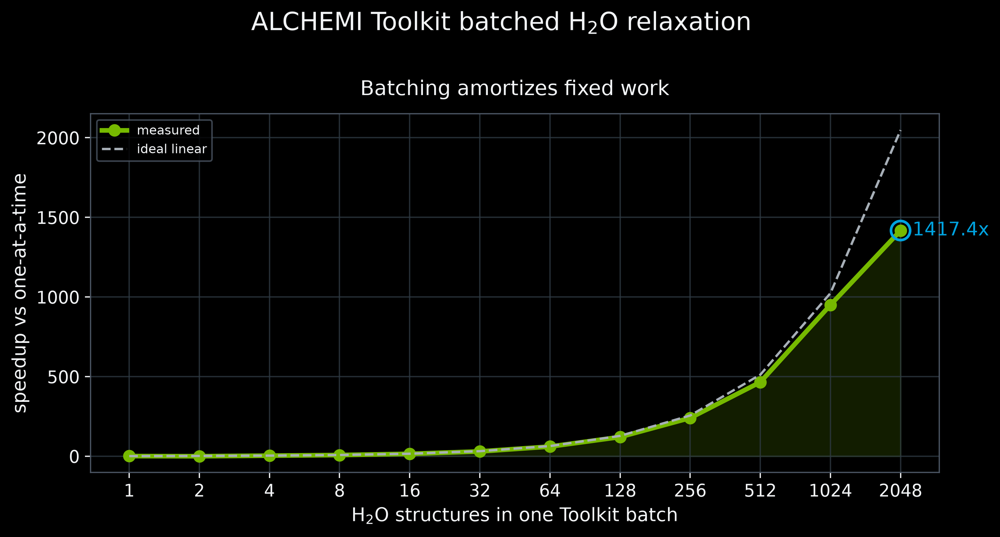

Saved figure: outputs/live_runs/20260617-064858/tutorial/h2o_speedup_full/figures/h2o_toolkit_batch_speedup.png


measured batch sizes,fastest batch size,fastest throughput (structures/s),largest-batch speedup,E(H2O molecule) (eV),full CSV
12,2048,5724.0,1417.4x,-13.7856,outputs/live_runs/20260617-064858/tutorial/h2o_speedup_full/tables/h2o_toolkit_batch_speedup.csv


In [8]:
# Step 6: run the H2O batches, compute speedup, and display the figure.
# One unreported warm-up pass keeps the plot focused on batching rather
# than first-call CUDA/kernel setup.
run_h2o_batch_timing(
    h2o_model,
    1,
    device=toolkit_device,
    dtype=toolkit_dtype,
    n_steps=H2O_BENCH_STEPS,
    dt=H2O_DT,
    fmax=H2O_FMAX,
)
h2o_speedup_rows = []
progress = NotebookProgress(
    title="Toolkit batch sweep",
    total=len(H2O_BATCH_SIZES),
    unit="batch sizes",
    message="warmup complete; starting H2O batches",
    average_label="s/batch run",
    width_px=560,
)
for index, size in enumerate(H2O_BATCH_SIZES, start=1):
    progress.update(done=index - 1, message=f"running batch size {size}")
    h2o_speedup_rows.append(
        run_h2o_batch_timing(
            h2o_model,
            size,
            device=toolkit_device,
            dtype=toolkit_dtype,
            n_steps=H2O_BENCH_STEPS,
            dt=H2O_DT,
            fmax=H2O_FMAX,
        )
    )
    progress.update(done=index, message=f"finished batch size {size}")

h2o_speedup_df = pd.DataFrame(h2o_speedup_rows)
os.makedirs(os.path.dirname(H2O_SPEEDUP_CACHE), exist_ok=True)
h2o_speedup_df.to_csv(H2O_SPEEDUP_CACHE, index=False)

# "One at a time" is an idealized serial baseline: N x the measured batch-size-1
# wall time. The measured quantity is throughput; the ratio is the speedup.
single_time = float(
    h2o_speedup_df.loc[h2o_speedup_df["batch_size"] == 1, "wall_time_s"].iloc[0]
)
h2o_speedup_df["one_at_a_time_s"] = single_time * h2o_speedup_df["batch_size"]
h2o_speedup_df["speedup_vs_single"] = (
    h2o_speedup_df["one_at_a_time_s"] / h2o_speedup_df["wall_time_s"]
)
E_H2O_molecule = float(
    h2o_speedup_df.loc[h2o_speedup_df["batch_size"] == 1, "energy_mean_eV"].iloc[0]
)

H2O_SPEEDUP_FIGURE = plot_h2o_batch_speedup(
    speedup_df=h2o_speedup_df,
    examples=[],
    output_path=H2O_SPEEDUP_FIGURE,
)
display_inline(H2O_SPEEDUP_FIGURE)

h2o_best = h2o_speedup_df.loc[h2o_speedup_df["structures_per_s"].idxmax()]
h2o_largest = h2o_speedup_df.sort_values("batch_size").iloc[-1]
h2o_summary = pd.DataFrame(
    [
        {
            "measured batch sizes": len(h2o_speedup_df),
            "fastest batch size": int(h2o_best["batch_size"]),
            "fastest throughput (structures/s)": float(h2o_best["structures_per_s"]),
            "largest-batch speedup": float(h2o_largest["speedup_vs_single"]),
            "E(H2O molecule) (eV)": E_H2O_molecule,
            "full CSV": tutorial_relpath(H2O_SPEEDUP_CACHE),
        }
    ]
)
print(f"Saved figure: {tutorial_relpath(H2O_SPEEDUP_FIGURE)}")
display(
    styled_table(
        h2o_summary,
        fmt={
            "fastest throughput (structures/s)": "{:.1f}",
            "largest-batch speedup": "{:.1f}x",
            "E(H2O molecule) (eV)": "{:.4f}",
        },
    )
)


### Does the GPU always win? Overhead vs throughput

The speedup figure above invites a fair question: is the GPU always faster? Not for a single tiny system. A GPU call carries a roughly **fixed overhead** — kernel launches, host↔device transfers, Python dispatch — that does not shrink as the system gets smaller. **Batching amortizes that fixed cost over many structures**, so GPU throughput climbs with batch size, while a CPU — little launch overhead but far less parallelism — stays comparatively flat.

The cell below times both devices across **two system sizes** — a single H₂O molecule (3 atoms) and a larger adsorbate-on-slab system (tens of atoms) — and plots throughput vs batch size for each. Where the curves cross is the batch size past which the GPU is the better choice; for the larger system the GPU pulls ahead at a much smaller batch, because each structure does more work per fixed-overhead call.

<div style="border-left:5px solid #00a3e0; background:#eef7fb; padding:12px 16px; margin:12px 0; border-radius:6px; font-family:Inter, Arial, sans-serif;"><div style="font-weight:700; color:#00a3e0; margin-bottom:5px; font-size:0.9em; letter-spacing:0.03em; text-transform:uppercase;">⚖️ Reading this fairly</div><div style="color:#1f2937; font-size:0.95em; line-height:1.5;">Both devices are warmed up once before timing; the CPU run pins and reports its thread count (more threads → faster CPU, up to a point); and the GPU path may use cuEquivariance kernels while the CPU cannot — so this is a <strong>deployment-realistic</strong> comparison, not a kernel-for-kernel one. Larger CPU batches are slow (that is the point), so they come from a shipped cache; throughput numbers are hardware-specific and the figure caption records the exact GPU and CPU-thread settings used.</div></div>

Using medium MPA-0 model as default MACE-MP model, to use previous (before 3.10) default model please specify 'medium' as model argument
Using medium MPA-0 model as default MACE-MP model, to use previous (before 3.10) default model please specify 'medium' as model argument


/opt/conda/envs/alchemi-playbook/lib/python3.12/site-packages/mace/modules/models.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "atomic_numbers", torch.tensor(atomic_numbers, dtype=torch.int64)


HTML(value='\n        <style>\n          html, body, .jp-RenderedHTMLCommon, .output_html {\n            backg…

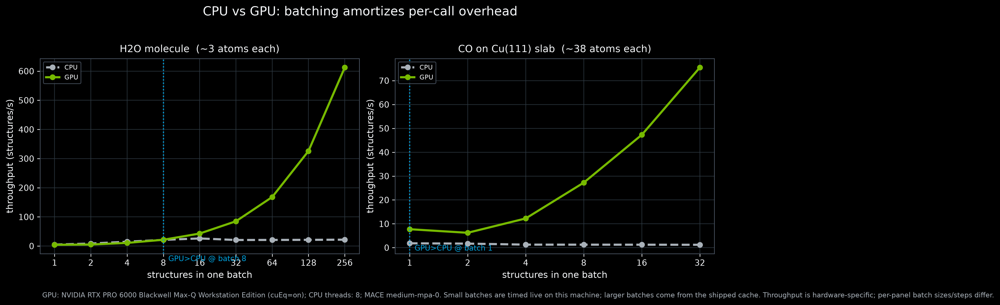

Saved: outputs/live_runs/20260617-064858/tutorial/device_throughput/figures/cpu_vs_gpu_throughput.png


In [9]:
# Measure CPU vs GPU throughput across two system sizes: a 3-atom H2O molecule
# and a larger adsorbate-on-slab system. Small batch sizes run live; larger
# (slow-on-CPU) sizes come from the shipped cache. The timing loop is the same
# helpers.time_relaxation_batch used elsewhere.
from helpers import (
    load_or_run_device_throughput_comparison,
    plot_device_throughput_comparison,
)

DEVICE_COMPARE_SYSTEMS = [
    {
        "label": "H2O molecule",
        "kind": "h2o",
        "live": [1, 2, 4, 8],
        "cached": [16, 32, 64, 128, 256],
        "n_steps": 15,
    },
    {
        "label": "CO on Cu(111) slab",
        "kind": "slab",
        "host": "Cu(111)",
        "adsorbate": "CO",
        "live": [1, 2],
        "cached": [4, 8, 16, 32],
        "n_steps": 8,
    },
]
DEVICE_COMPARE_CPU_THREADS = max(1, min(8, (os.cpu_count() or 8) // 2))

# Same output contract as the adsorption sweep: TUTORIAL_OUTPUT_DIR points at the
# shipped precomputed folder in "saved" mode and the live-run folder in "compute".
DEVICE_COMPARE_ROOT = os.path.join(TUTORIAL_OUTPUT_DIR, "device_throughput")
DEVICE_COMPARE_CACHE = os.path.join(
    DEVICE_COMPARE_ROOT, "tables", "cpu_vs_gpu_throughput.csv"
)
DEVICE_COMPARE_FIGURE = os.path.join(
    DEVICE_COMPARE_ROOT, "figures", "cpu_vs_gpu_throughput.png"
)
if USE_SAVED_TUTORIAL_RESULTS and not REFRESH_SAVED_RESULTS:
    DEVICE_COMPARE_FIGURE = os.path.join(
        LIVE_OUTPUT_DIR, "tutorial", "plots", "cpu_vs_gpu_throughput.png"
    )

device_results, device_compare_meta = load_or_run_device_throughput_comparison(
    systems=DEVICE_COMPARE_SYSTEMS,
    use_precomputed=USE_SAVED_TUTORIAL_RESULTS,
    checkpoint="medium-mpa-0",
    dtype=toolkit_dtype,
    cache_path=DEVICE_COMPARE_CACHE,
    dt=H2O_DT,
    fmax=H2O_FMAX,
    enable_cueq=TOOLKIT_ENABLE_CUEQ,
    compile_model=TOOLKIT_COMPILE_MODEL,
    cpu_threads=DEVICE_COMPARE_CPU_THREADS,
    gpu_available=(toolkit_device.type == "cuda"),
    progress_factory=NotebookProgress,
    relpath_fn=tutorial_relpath,
)

device_compare_caption = (
    f"GPU: {device_compare_meta['gpu_name']} "
    f"(cuEq={'on' if device_compare_meta['enable_cueq_gpu'] else 'off'}); "
    f"CPU threads: {device_compare_meta['cpu_threads']}; "
    f"MACE {device_compare_meta['checkpoint']}. "
    "Small batches are timed live on this machine; larger batches come from the "
    "shipped cache. Throughput is hardware-specific; per-panel batch sizes/steps differ."
)
DEVICE_COMPARE_FIGURE = plot_device_throughput_comparison(
    device_results,
    output_path=DEVICE_COMPARE_FIGURE,
    caption=device_compare_caption,
)
display_inline(DEVICE_COMPARE_FIGURE)
print(f"Saved: {tutorial_relpath(DEVICE_COMPARE_FIGURE)}")


### Adsorption batch-size sweep

The H<sub>2</sub>O figure isolates the batching idea. Research runs like adsorption batches are heavier: each item includes a slab, an adsorbate, periodic boundaries, frozen atoms, and neighbor lists. Before a longer search, it is useful to measure the practical throughput/memory trade-off for the actual chemistry.

Here we run a short H<sub>2</sub>O/TiO<sub>2</sub>(110) relaxation pool and compare open MACE choices:

- `MACE-MPA-0 medium`: the open default used for validation and the main adsorption screen later in the notebook.
- `MACE-MP-0 small`: a smaller open checkpoint that is useful for seeing the lower-memory, higher-throughput end of the trade-off.
- `MACE-MP-0 large`: a larger open checkpoint that gives the same workflow a different memory and throughput profile.

This tutorial uses MACE-MP/MACE-MPA checkpoints only. MACE-MH-1 with the OC20 surface head is the surface-specialized follow-up we would test next; its model card reports OC20/surface heads and surface-adsorption benchmarks. It is beyond the scope of this runnable NVIDIA tutorial because the upstream model is ASL-licensed, so no shipped outputs here are produced with MH-1. See the [MACE-MH-1 model card](https://huggingface.co/mace-foundations/mace-mh-1) and [MACE foundation-model repository](https://github.com/ACEsuit/mace-foundations).

A larger or more specialized model is not automatically too expensive for a batched workflow; likewise, larger model doesn't guarantee better accuracy. We measure memory and structures/s because the best batch size depends on the model, system size, and GPU. The sweep keeps increasing batch size until throughput flattens or memory becomes limiting; the recommended batch is the smallest measured batch near the best structures/s rate while staying under a realistic VRAM headroom rule. This sweep varies two things at once — batch size and model size — so read it as a throughput/memory envelope across open MACE options; the recommended batch size for the screen later in the notebook is taken from the `medium-mpa-0` curve, the model used for the rest of the workflow.


In [10]:
# First visual check: one H2O/TiO2(110) starting geometry before the surface batch-size sweep.
# The same structure-building path feeds the short performance sweep below;
# seeing the actual slab + adsorbate first makes the timing plot less abstract.
from helpers import build_config_grid

TIO2_PREVIEW_HOST = "TiO2(110)"
TIO2_PREVIEW_ADSORBATE = "H2O"

h2o_tio2_preview_pool = build_config_grid(
    host_name=TIO2_PREVIEW_HOST,
    adsorbate_name=TIO2_PREVIEW_ADSORBATE,
    rotations_deg=(0.0,),
    heights_A=(2.2,),
)
h2o_tio2_preview = h2o_tio2_preview_pool[0]
print(
    f"Preview structure: {h2o_tio2_preview.label} | atoms={len(h2o_tio2_preview.atoms)}"
)
display_widgets_row(
    [("H2O on TiO2(110) starting geometry", h2o_tio2_preview.atoms)],
    width="360px",
    height="300px",
    show_cell=True,
    wrap_periodic_cell=True,
)

Preview structure: H2O_TiO2(110)_ti-top_O-down_rot0_h2.2 | atoms=75


In [11]:
# Adsorption batch-size sweep setup: short relaxations on a representative oxide-surface pool.
ADSORPTION_BATCH_SWEEP_HOST = "TiO2(110)"
ADSORPTION_BATCH_SWEEP_ADSORBATE = "H2O"
ADSORPTION_BATCH_SWEEP_TAG = "h2o_tio2_110_open_mace"
ADSORPTION_BATCH_SWEEP_BATCH_SIZES = {
    "short": [4, 8, 12],
    "full": [4, 8, 12, 16, 24, 32, 48, 64, 96],
}[RUN_SCOPE]
ADSORPTION_BATCH_SWEEP_STEPS = 40
ADSORPTION_BATCH_SWEEP_DT = (
    0.01  # short FIRE2 step size used only for this batch-size sweep
)
ADSORPTION_BATCH_SWEEP_MEMORY_FRACTION = 0.80
ADSORPTION_BATCH_SWEEP_MODELS = [
    {"label": "MACE-MPA-0 medium", "checkpoint": "medium-mpa-0", "head": None},
    {"label": "MACE-MP-0 small", "checkpoint": "small", "head": None},
    {"label": "MACE-MP-0 large", "checkpoint": "large", "head": None},
]
ADSORPTION_BATCH_SWEEP_ROOT = os.path.join(
    TUTORIAL_OUTPUT_DIR,
    f"adsorption_batch_sweep_{ADSORPTION_BATCH_SWEEP_TAG}_{RUN_SCOPE}",
)
ADSORPTION_BATCH_SWEEP_FULL_ROOT = os.path.join(
    TUTORIAL_OUTPUT_DIR, f"adsorption_batch_sweep_{ADSORPTION_BATCH_SWEEP_TAG}_full"
)
ADSORPTION_BATCH_SWEEP_CACHE = os.path.join(
    ADSORPTION_BATCH_SWEEP_ROOT, "tables", "adsorption_batch_sweep.csv"
)
ADSORPTION_BATCH_SWEEP_FULL_CACHE = os.path.join(
    ADSORPTION_BATCH_SWEEP_FULL_ROOT, "tables", "adsorption_batch_sweep.csv"
)
ADSORPTION_BATCH_SWEEP_FIGURE = os.path.join(
    ADSORPTION_BATCH_SWEEP_ROOT, "figures", "adsorption_batch_sweep.png"
)
ADSORPTION_BATCH_SWEEP_FULL_FIGURE = os.path.join(
    ADSORPTION_BATCH_SWEEP_FULL_ROOT, "figures", "adsorption_batch_sweep.png"
)

print(
    f"Sweep chemistry            : {ADSORPTION_BATCH_SWEEP_ADSORBATE} on {ADSORPTION_BATCH_SWEEP_HOST}"
)
print(f"Short relaxation cap       : {ADSORPTION_BATCH_SWEEP_STEPS} optimizer steps")
print(f"Batch sizes to test        : {ADSORPTION_BATCH_SWEEP_BATCH_SIZES}")
print(
    "Models to test             : "
    + ", ".join(spec["label"] for spec in ADSORPTION_BATCH_SWEEP_MODELS)
)

Sweep chemistry            : H2O on TiO2(110)
Short relaxation cap       : 40 optimizer steps
Batch sizes to test        : [4, 8, 12, 16, 24, 32, 48, 64, 96]
Models to test             : MACE-MPA-0 medium, MACE-MP-0 small, MACE-MP-0 large


Batch-size sweep pool: 27 starting structures; larger batches cycle through this pool to measure GPU throughput.


HTML(value='\n        <style>\n          html, body, .jp-RenderedHTMLCommon, .output_html {\n            backg…

Using medium MPA-0 model as default MACE-MP model, to use previous (before 3.10) default model please specify 'medium' as model argument


/opt/conda/envs/alchemi-playbook/lib/python3.12/site-packages/mace/modules/models.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "atomic_numbers", torch.tensor(atomic_numbers, dtype=torch.int64)
/opt/conda/envs/alchemi-playbook/lib/python3.12/site-packages/mace/modules/models.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "atomic_numbers", torch.tensor(atomic_numbers, dtype=torch.int64)
/opt/conda/envs/alchemi-playbook/lib/python3.12/site-packages/mace/modules/models.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "atomic

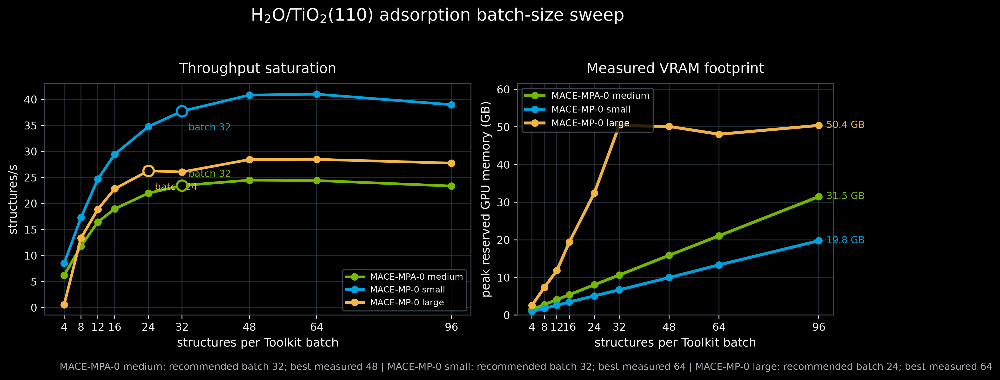

Saved: outputs/live_runs/20260617-064858/tutorial/adsorption_batch_sweep_h2o_tio2_110_open_mace_full/figures/adsorption_batch_sweep.png
Recommended adsorption batch sizes:
  MACE-MPA-0 medium: batch 32 (23.45 structures/s, 1759 atoms/s, 10.65 GB reserved footprint, 10.39 GB observed free-VRAM drop)
  MACE-MP-0 small: batch 32 (37.72 structures/s, 2829 atoms/s, 6.71 GB reserved footprint, 6.46 GB observed free-VRAM drop)
  MACE-MP-0 large: batch 24 (26.27 structures/s, 1971 atoms/s, 32.44 GB reserved footprint, 32.13 GB observed free-VRAM drop)
Full timing rows are saved to CSV; the figure shows throughput saturation and measured VRAM footprint.
Detailed timing rows: outputs/live_runs/20260617-064858/tutorial/adsorption_batch_sweep_h2o_tio2_110_open_mace_full/tables/adsorption_batch_sweep.csv


In [12]:
# Run or load the adsorption batch-size sweep, then show the performance figure.
from IPython.display import Markdown, display

(
    adsorption_batch_sweep_df,
    adsorption_batch_sweep_summary,
    adsorption_batch_sweep_cache_source,
) = load_or_run_adsorption_batch_sweep(
    use_precomputed=USE_SAVED_TUTORIAL_RESULTS,
    run_scope=RUN_SCOPE,
    batch_sizes=ADSORPTION_BATCH_SWEEP_BATCH_SIZES,
    cache_path=ADSORPTION_BATCH_SWEEP_CACHE,
    full_cache_path=ADSORPTION_BATCH_SWEEP_FULL_CACHE,
    tutorial_relpath=tutorial_relpath,
    host_name=ADSORPTION_BATCH_SWEEP_HOST,
    adsorbate_name=ADSORPTION_BATCH_SWEEP_ADSORBATE,
    model_specs=ADSORPTION_BATCH_SWEEP_MODELS,
    output_dir=TUTORIAL_OUTPUT_DIR,
    toolkit_device=("cuda" if TOOLKIT_DEVICE == "auto" else TOOLKIT_DEVICE),
    toolkit_dtype=TOOLKIT_DTYPE,
    toolkit_dt=ADSORPTION_BATCH_SWEEP_DT,
    n_steps=ADSORPTION_BATCH_SWEEP_STEPS,
    memory_fraction=ADSORPTION_BATCH_SWEEP_MEMORY_FRACTION,
    compile_model=TOOLKIT_COMPILE_MODEL,
    enable_cueq=TOOLKIT_ENABLE_CUEQ,
    progress_factory=NotebookProgress,
    display_fn=display,
    markdown_cls=Markdown,
)

batch_sweep_figure_path = ADSORPTION_BATCH_SWEEP_FIGURE
if USE_SAVED_TUTORIAL_RESULTS and not REFRESH_SAVED_RESULTS:
    batch_sweep_figure_path = os.path.join(
        LIVE_OUTPUT_DIR,
        "tutorial",
        "plots",
        f"adsorption_batch_sweep_{ADSORPTION_BATCH_SWEEP_TAG}_{RUN_SCOPE}.png",
    )

ADSORPTION_BATCH_SWEEP_FIGURE = plot_adsorption_batch_sweep(
    adsorption_batch_sweep_df,
    output_path=batch_sweep_figure_path,
    title="H$_2$O/TiO$_2$(110) adsorption batch-size sweep",
)
display_inline(ADSORPTION_BATCH_SWEEP_FIGURE)
print(f"Saved: {tutorial_relpath(ADSORPTION_BATCH_SWEEP_FIGURE)}")

display_adsorption_batch_sweep_results(
    adsorption_batch_sweep_df,
    adsorption_batch_sweep_summary,
    display_fn=display,
    markdown_cls=Markdown,
)
print(f"Detailed timing rows: {tutorial_relpath(adsorption_batch_sweep_cache_source)}")

### Model selection and validation: speed is not enough

The H<sub>2</sub>O/TiO<sub>2</sub>(110) example shows what batching changes computationally: a GPU can relax many molecule-on-surface structures at once instead of repeating the same small calculation one structure at a time. Before we use that throughput for a larger adsorption search, we need the model choice to be explicit.

For this tutorial, the practical model question is:

> **Can this open MACE model give useful answers for molecule-on-surface chemistry at the scale we want to run?**

That is a joint question about chemistry, speed, memory, licensing, and sometimes the researcher's preference. We keep the runnable path on open MACE models, then compare against released OC20Dense DFT data so the notebook has a reference point: the starting structures, relaxed DFT geometries, and adsorption-energy targets come from a published surface-chemistry benchmark, while the calculations below are rerun with the Toolkit/MACE path.

We use two compact checks:

- **Relaxation check:** replay three released OC20Dense adsorption trajectories from their published starting frames. For one H<sub>2</sub>O, one NH<sub>3</sub>, and one N<sub>2</sub> case, the notebook writes the MACE relaxation trajectory and compares its endpoint with the released DFT trajectory endpoint: final adsorption energy, adsorbate geometry, and RMSD.
- **Ranking check:** take 92 DFT-relaxed NH<sub>3</sub> configurations for the same surface system, evaluate them in one batched single-point calculation, and ask whether MACE preserves the same relative adsorption landscape. Energies are shifted to the DFT rank-1 geometry, so the comparison focuses on ranking rather than an arbitrary absolute zero.

H<sub>2</sub>O, NH<sub>3</sub>, and N<sub>2</sub> are used here because their neutral gas references are unambiguous. D3 corrections are available in Toolkit workflows, but they stay off in this validation because the OC20Dense reference targets used here follow the non-D3 OC20 convention.

`VALIDATION_RESULT_SOURCE` controls this section. The default is `"compute"`; set it to `"saved"` in the control panel when you want to inspect saved validation tables without rerunning the validation check.


`make_oc20dense_validation_context` is a thin constructor that bundles every choice made above (the three trajectory cases, the NH<sub>3</sub> ranking system, the model checkpoint and head, the batch sizes, the convergence tolerance) into a single frozen `OC20DenseValidationContext` handle. The downstream cells carry that handle instead of passing the same arguments through every function; if any of those values change, only this cell rebuilds the context and the rest of the validation section picks it up.

In [13]:
from helpers import make_oc20dense_validation_context

# Validation settings: choose the examples, ranks, and model used for this checkpoint.
from IPython.display import Markdown, display

VALIDATION_TOOLKIT_CHECKPOINT = "medium-mpa-0"
VALIDATION_TOOLKIT_HEAD = None

TRAJECTORY_VALIDATION_SELECTION = [
    {
        "system_id": "3_2070_48",
        "config_id": "rand64",
        "sid": 14966,
        "adsorbate": "H2O",
        "dft_rank": 1,
    },
    {
        "system_id": "72_7104_115",
        "config_id": "rand27",
        "sid": 3469,
        "adsorbate": "NH3",
        "dft_rank": 1,
    },
    {
        "system_id": "69_1615_2",
        "config_id": "rand2",
        "sid": 23355,
        "adsorbate": "N2",
        "dft_rank": 1,
    },
]

NH3_RANKING_SYSTEM = "72_7104_115"
NH3_RANKING_PREVIEW_RANKS = [1, 4, 16, 92]
SHOW_ALL_NH3_RANKING = False

VALIDATION_SINGLE_POINT_BATCH_SIZE = 12
VALIDATION_TOOLKIT_N_STEPS = 200
VALIDATION_TOOLKIT_FMAX = 0.05  # eV/A force threshold for validation relaxations

validation_context = make_oc20dense_validation_context(
    tutorial_root=TUTORIAL_ROOT,
    accuracy_output_dir=ACCURACY_OUTPUT_DIR,
    result_source=VALIDATION_RESULT_SOURCE,
    checkpoint=VALIDATION_TOOLKIT_CHECKPOINT,
    head=VALIDATION_TOOLKIT_HEAD,
    trajectory_selection=TRAJECTORY_VALIDATION_SELECTION,
    nh3_system=NH3_RANKING_SYSTEM,
    preview_ranks=NH3_RANKING_PREVIEW_RANKS,
    show_all_nh3_ranking=SHOW_ALL_NH3_RANKING,
    single_point_batch_size=VALIDATION_SINGLE_POINT_BATCH_SIZE,
    n_steps=VALIDATION_TOOLKIT_N_STEPS,
    fmax=VALIDATION_TOOLKIT_FMAX,
)

VALIDATION_MODEL_LABEL = validation_context.model_label
OC20DENSE_SOURCE_ROOT = validation_context.oc20dense_data_root
TRAJECTORY_VALIDATION_ROOT = validation_context.trajectory_root
NH3_RANKING_ROOT = validation_context.nh3_ranking_root

validation_choices_df = validation_context_table(
    validation_context, relpath_fn=tutorial_relpath
)
display(validation_choices_df.style.hide(axis="index"))

choice,value
result source,compute
model,medium-mpa-0
relaxation check,"3 OC20Dense starts (H2O, NH3, N2), Toolkit batch size 3"
NH3 ranking,"Ca3InP3(112) [mp-614572, system 72_7104_115, bottom side], 92 DFT-relaxed geometries, single-point batch size 12"
relaxation stop,"200 step cap, fmax <= 0.05 eV/A"
reference data,data/reference/oc20dense
trajectory output,outputs/live_runs/20260617-064858/accuracy/oc20dense_closed_shell_trajectory_mace_mpa0
NH3 ranking output,outputs/live_runs/20260617-064858/accuracy/oc20dense_nh3_92_fixed_geometry_mace_mpa0


### Run the validation

With `VALIDATION_RESULT_SOURCE = "compute"`, the next cell reruns the compact OC20Dense checkpoint directly from the Toolkit/Python workflow. With `"saved"`, it shows the saved result folders that feed the display cells without recomputing them.


`run_or_load_oc20dense_validation` is the orchestrator for this section. When the context's `result_source` is `"compute"`, it relaxes the three trajectories and runs the 92-config NH<sub>3</sub> single-point sweep on the GPU, writes the result tables under `ACCURACY_OUTPUT_DIR`, and returns the timing summary shown below. When `result_source` is `"saved"`, it skips the GPU work and points the display cells at the previously-written tables. Either way, the downstream display cells consume the same artefacts.

In [14]:
from helpers import run_or_load_oc20dense_validation

# Compute the validation checkpoint, or show the saved sources selected above.
validation_runtime_df = run_or_load_oc20dense_validation(
    validation_context,
    progress_factory=NotebookProgress,
    display_fn=None,
    relpath_fn=tutorial_relpath,
)

display(
    Markdown(
        "Elapsed times below are notebook-side work: Toolkit recomputation plus lookup "
        "and consistency checks against released DFT reference records. No DFT is run here."
    )
)
display(validation_runtime_df)

HTML(value='\n        <style>\n          html, body, .jp-RenderedHTMLCommon, .output_html {\n            backg…

Sets are not currently considered sequences, but this may change in the future, so consider avoiding using them.


Elapsed times below are notebook-side work: Toolkit recomputation plus lookup and consistency checks against released DFT reference records. No DFT is run here.

,validation check,timed action,elapsed_min,log
0,relaxation check,Toolkit relaxation batch,0.096080,outputs/live_runs/20260617-064858/accuracy/rep...
1,relaxation check,Released DFT reference lookup and RMSD check,0.006815,outputs/live_runs/20260617-064858/accuracy/rep...
2,relaxation check,Toolkit adsorption-energy recomputation,0.114546,outputs/live_runs/20260617-064858/accuracy/rep...
3,NH3 fixed-geometry ranking,Released DFT ranking lookup for all 92 NH3 str...,0.239565,outputs/live_runs/20260617-064858/accuracy/rep...
4,NH3 fixed-geometry ranking,Toolkit single-point scoring on 92 DFT-final g...,0.161088,outputs/live_runs/20260617-064858/accuracy/rep...


In [15]:
# Relaxation check: compare MACE-relaxed endpoints with released DFT trajectories.
from helpers.validation_workflows import (
    show_trajectory_validation_results,
    validation_trajectory_artifact_paths,
)

trajectory_validation = show_trajectory_validation_results(
    validation_context,
    display_fn=display,
    markdown_cls=Markdown,
)
trajectory_per_config = trajectory_validation["trajectory_per_config"]
trajectory_dft_reference = trajectory_validation["trajectory_dft_reference"]
trajectory_mace_results = trajectory_validation["trajectory_mace_results"]
trajectory_mace_refs = trajectory_validation["trajectory_mace_refs"]
trajectory_relaxation_errors = trajectory_validation["trajectory_relaxation_errors"]
max_trajectory_dft_target_delta_eV = trajectory_validation[
    "max_trajectory_dft_target_delta_eV"
]

# Resolve the DFT and Toolkit trajectory files used by the video render below.
trajectory_video_paths = validation_trajectory_artifact_paths(
    validation_context,
    trajectory_validation,
)
display(Markdown("#### DFT and Toolkit trajectory files for MP4 rendering"))
display(
    trajectory_video_paths.assign(
        dft_trajectory_path=lambda df: df["dft_trajectory_path"].map(tutorial_relpath),
        toolkit_trajectory_path=lambda df: df["toolkit_trajectory_path"].map(
            tutorial_relpath
        ),
    ).style.hide(axis="index")
)

#### Relaxation check: Toolkit trajectories against OC20Dense DFT

adsorbate,system_id,config_id,DFT Eads (eV),MACE relaxed Eads (eV),Eads error (eV),"all-atom RMSD, MIC (A)"
*OH2,3_2070_48,rand64,-0.542908,-1.200003,-0.657095,0.149144
*N2,69_1615_2,rand2,-0.081494,-0.179314,-0.097819,0.261362
*NH3,72_7104_115,rand27,-2.049714,-1.395977,0.653737,0.446346


RMSD is reported for all atoms using the exact OC20Dense atom order and the minimum-image convention for periodic boundaries.

Largest MACE-vs-DFT relaxed-endpoint miss in this compact slice: `*OH2`: Eads error `-0.657 eV`, all-atom RMSD `0.149 A`.

#### Toolkit/MACE reference terms used for relaxed Eads

These clean-surface and gas terms are recomputed with `medium-mpa-0` so the MACE-relaxed adsorption energy uses one consistent model. The DFT comparison column above comes from the released OC20Dense adsorption-energy target.

system_id,isolated gas molecule,Toolkit/MACE gas energy (eV),gas_converged,gas steps,Toolkit/MACE clean-surface energy (eV),surface fmax after Toolkit/MACE relaxation (eV/A)
3_2070_48,H2O,-13.786341,True,16,-53.237144,0.049760
72_7104_115,NH3,-18.995319,True,39,-351.465271,0.047049
69_1615_2,N2,-16.433846,True,13,-142.022369,0.043041


#### DFT and Toolkit trajectory files for MP4 rendering

system_id,config_id,sid,adsorbate,dft_trajectory_path,toolkit_trajectory_path,dft_trajectory_widget_path,mace_trajectory_widget_path
3_2070_48,rand64,14966,*OH2,outputs/live_runs/20260617-064858/accuracy/oc20dense_closed_shell_trajectory_mace_mpa0/dft_reference_checks/dft_trajectories_extxyz/3_2070_48_rand64_sid14966.extxyz,outputs/live_runs/20260617-064858/accuracy/oc20dense_closed_shell_trajectory_mace_mpa0/structures/toolkit_trajectories/3_2070_48_rand64_sid14966.extxyz,/workspace/part-1-batched-adsorption-toolkit/outputs/live_runs/20260617-064858/accuracy/oc20dense_closed_shell_trajectory_mace_mpa0/dft_reference_checks/dft_trajectories_extxyz/3_2070_48_rand64_sid14966.extxyz,/workspace/part-1-batched-adsorption-toolkit/outputs/live_runs/20260617-064858/accuracy/oc20dense_closed_shell_trajectory_mace_mpa0/structures/toolkit_trajectories/3_2070_48_rand64_sid14966.extxyz
72_7104_115,rand27,3469,*NH3,outputs/live_runs/20260617-064858/accuracy/oc20dense_closed_shell_trajectory_mace_mpa0/dft_reference_checks/dft_trajectories_extxyz/72_7104_115_rand27_sid3469.extxyz,outputs/live_runs/20260617-064858/accuracy/oc20dense_closed_shell_trajectory_mace_mpa0/structures/toolkit_trajectories/72_7104_115_rand27_sid3469.extxyz,/workspace/part-1-batched-adsorption-toolkit/outputs/live_runs/20260617-064858/accuracy/oc20dense_closed_shell_trajectory_mace_mpa0/dft_reference_checks/dft_trajectories_extxyz/72_7104_115_rand27_sid3469.extxyz,/workspace/part-1-batched-adsorption-toolkit/outputs/live_runs/20260617-064858/accuracy/oc20dense_closed_shell_trajectory_mace_mpa0/structures/toolkit_trajectories/72_7104_115_rand27_sid3469.extxyz
69_1615_2,rand2,23355,*N2,outputs/live_runs/20260617-064858/accuracy/oc20dense_closed_shell_trajectory_mace_mpa0/dft_reference_checks/dft_trajectories_extxyz/69_1615_2_rand2_sid23355.extxyz,outputs/live_runs/20260617-064858/accuracy/oc20dense_closed_shell_trajectory_mace_mpa0/structures/toolkit_trajectories/69_1615_2_rand2_sid23355.extxyz,/workspace/part-1-batched-adsorption-toolkit/outputs/live_runs/20260617-064858/accuracy/oc20dense_closed_shell_trajectory_mace_mpa0/dft_reference_checks/dft_trajectories_extxyz/69_1615_2_rand2_sid23355.extxyz,/workspace/part-1-batched-adsorption-toolkit/outputs/live_runs/20260617-064858/accuracy/oc20dense_closed_shell_trajectory_mace_mpa0/structures/toolkit_trajectories/69_1615_2_rand2_sid23355.extxyz


In [16]:
# Optional: render the validation trajectories as browser-safe MP4s.
# This is off by default for the barebones tutorial path because it requires
# a working OVITO renderer and can take about a minute on the reference runtime.
import importlib
import os
import sys
from pathlib import Path

current_tutorial_root = Path.cwd().resolve()
if not (current_tutorial_root / "helpers" / "__init__.py").exists():
    raise RuntimeError(
        "Start this kernel from the tutorial folder before rendering trajectories."
    )
TUTORIAL_ROOT = current_tutorial_root
sys.path[:] = [
    str(TUTORIAL_ROOT),
    *[
        entry
        for entry in sys.path
        if entry
        and Path(entry).resolve() != TUTORIAL_ROOT
        and not (
            Path(entry).resolve() / "alchemi-mace-adsorption-search.ipynb"
        ).exists()
    ],
]
for module_name in [
    name
    for name in list(sys.modules)
    if name == "helpers" or name.startswith("helpers.")
]:
    del sys.modules[module_name]
importlib.invalidate_caches()

from helpers.visualization import (
    display_validation_trajectory_videos,
    render_validation_trajectory_videos,
)

RENDER_VALIDATION_TRAJECTORY_VIDEO = True
VALIDATION_TRAJECTORY_RENDERER = (
    "visrtx"  # Set to "visrtx" on a configured RTX Linux runtime.
)
VALIDATION_TRAJECTORY_SAMPLES_PER_PIXEL = 12
VALIDATION_TRAJECTORY_TARGET_FRAMES = 240
VALIDATION_TRAJECTORY_FPS = 30
INSTALL_FFMPEG_IF_MISSING = False

if RENDER_VALIDATION_TRAJECTORY_VIDEO:
    VALIDATION_TRAJECTORY_VIDEO_DIR = os.path.join(
        ACCURACY_OUTPUT_DIR,
        "renders",
        "validation_trajectory_mp4_tiles_v12_centered",
    )
    trajectory_video_grid = render_validation_trajectory_videos(
        trajectory_video_paths,
        output_dir=VALIDATION_TRAJECTORY_VIDEO_DIR,
        renderer=VALIDATION_TRAJECTORY_RENDERER,
        samples_per_pixel=VALIDATION_TRAJECTORY_SAMPLES_PER_PIXEL,
        frames=VALIDATION_TRAJECTORY_TARGET_FRAMES,
        fps=VALIDATION_TRAJECTORY_FPS,
        width=960,
        height=720,
        install_ffmpeg_if_missing=INSTALL_FFMPEG_IF_MISSING,
        progress_factory=None,
    )
    display_validation_trajectory_videos(
        trajectory_video_grid,
        output_dir=VALIDATION_TRAJECTORY_VIDEO_DIR,
        relpath_fn=tutorial_relpath,
        width=420,
    )
else:
    display(
        Markdown(
            "Trajectory MP4 rendering is skipped in the barebones run. Set "
            "`RENDER_VALIDATION_TRAJECTORY_VIDEO = True` when the active kernel has "
            "OVITO rendering and FFmpeg available."
        )
    )

Rendered 6 centered orthographic MP4 files under `outputs/live_runs/20260617-064858/accuracy/renders/validation_trajectory_mp4_tiles_v12_centered` and transcoded browser-safe copies. OVITO render wall time: 22.9 s.

,label,DFT render (s),Toolkit render (s),OVITO render total (s),DFT frames,Toolkit frames,DFT s/frame,Toolkit s/frame,DFT transcode (s),Toolkit transcode (s),renderer,width,height,fps
0,*OH2 | 3_2070_48 | rand64,3.24,3.89,7.13,167,200,0.02,0.02,0.18,0.19,visrtx (spp=12),960,720,30
1,*NH3 | 72_7104_115 | rand27,3.09,3.77,6.86,168,200,0.02,0.02,0.18,0.18,visrtx (spp=12),960,720,30
2,*N2 | 69_1615_2 | rand2,3.99,4.25,8.24,194,200,0.02,0.02,0.20,0.21,visrtx (spp=12),960,720,30


#### *OH2 | 3_2070_48 | rand64 | DFT reference trajectory

[Open DFT MP4](outputs/live_runs/20260617-064858/accuracy/renders/validation_trajectory_mp4_tiles_v12_centered/pair_01/dft_browser.mp4)

#### *OH2 | 3_2070_48 | rand64 | Toolkit/MACE trajectory

[Open Toolkit MP4](outputs/live_runs/20260617-064858/accuracy/renders/validation_trajectory_mp4_tiles_v12_centered/pair_01/toolkit_browser.mp4)

... (4 outputs left out)

#### *N2 | 69_1615_2 | rand2 | DFT reference trajectory

[Open DFT MP4](outputs/live_runs/20260617-064858/accuracy/renders/validation_trajectory_mp4_tiles_v12_centered/pair_03/dft_browser.mp4)

#### *N2 | 69_1615_2 | rand2 | Toolkit/MACE trajectory

[Open Toolkit MP4](outputs/live_runs/20260617-064858/accuracy/renders/validation_trajectory_mp4_tiles_v12_centered/pair_03/toolkit_browser.mp4)

In [17]:
# Fixed-geometry ranking: score all 92 NH3 DFT-relaxed final geometries in batches.
from helpers.validation_workflows import show_nh3_ranking_results

nh3_ranking_results = show_nh3_ranking_results(
    validation_context,
    display_fn=display,
    markdown_cls=Markdown,
)
ranking_dft_reference = nh3_ranking_results["ranking_dft_reference"]
ranking_dft_final_sp = nh3_ranking_results["ranking_dft_final_sp"]
nh3_ranking_all = nh3_ranking_results["nh3_ranking_all"]
rank1_summary = nh3_ranking_results["rank1_summary"]
max_ranking_dft_target_delta_eV = nh3_ranking_results["max_ranking_dft_target_delta_eV"]
max_ranking_start_adsorbate_rmsd_A = nh3_ranking_results[
    "max_ranking_start_adsorbate_rmsd_A"
]

#### Fixed-geometry NH<sub>3</sub> ranking: 92 DFT-relaxed structures

DFT rank,config_id,sid,DFT gap from DFT-best (eV),MACE gap from DFT-best geometry (eV),"relative-energy error, MACE - DFT (eV)",MACE rank
1,rand27,3469,0.000000,0.000000,0.000000,6
2,rand13,13996,0.011468,-0.048920,-0.060388,2
3,heur8,56261,0.012765,-0.049683,-0.062447,1
4,rand16,40768,0.021999,-0.032990,-0.054988,4
5,rand12,22015,0.154065,0.092255,-0.061810,10
6,heur36,72835,0.155021,0.137573,-0.017448,17
7,rand6,9067,0.155246,0.151978,-0.003269,23
8,rand5,45787,0.155373,0.136932,-0.018441,15
9,heur1,197,0.155551,0.156952,0.001401,24
10,heur17,79002,0.156010,0.143311,-0.012699,20


Showing the first 10 and last 10 configurations by released DFT adsorption-energy rank. Set `SHOW_ALL_NH3_RANKING = True` in the validation settings cell to display all 92 rows.

Across all 92 fixed geometries, the DFT-best anchored relative-energy error is RMSE `0.1738 eV`, MAE `0.1452 eV`, bias `-0.1390 eV`, and Spearman rank correlation `0.786`.

The ranking metric compares relative gaps from the same DFT-best geometry: `E(row) - E(DFT-best)` for DFT and for MACE. Because all rows share the same surface and adsorbate, constant gas/surface offsets cancel. The relative-energy error is `MACE gap - DFT gap`.

#### NH<sub>3</sub> 92-configuration single-batch Toolkit API

Using medium MPA-0 model as default MACE-MP model, to use previous (before 3.10) default model please specify 'medium' as model argument


/opt/conda/envs/alchemi-playbook/lib/python3.12/site-packages/mace/modules/models.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "atomic_numbers", torch.tensor(atomic_numbers, dtype=torch.int64)


ASE structures,Toolkit Batch objects,MACE model calls,energies returned,device,total atoms,wall time (s),peak CUDA memory (GB)
92,1,1,92,cuda,8096,0.08,17.04


92 ASE structures became one Toolkit `Batch`; one MACE call returned 92 single-point energies plus forces for all atoms.

reference rank,config_id,sid,atoms,MACE single-point total energy (eV),max force (eV/A),MACE single-point rank
2,rand13,13996,88,-371.649536,1.2881,1
3,heur8,56261,88,-371.649139,1.2884,2
18,rand20,19718,88,-371.631744,1.2913,3
4,rand16,40768,88,-371.629700,1.2884,4
19,heur30,10702,88,-371.604919,1.2910,5
1,rand27,3469,88,-371.598083,1.2905,6
23,rand7,70174,88,-371.518402,1.2928,7
25,rand37,1723,88,-371.511658,1.2910,8


#### NH<sub>3</sub> 92-configuration visual scan

Rendering `92` DFT-final NH<sub>3</sub> geometries with `visrtx` at `640x480` px per tile on Ca<sub>3</sub>InP<sub>3</sub>(112) [mp-614572, system 72_7104_115, bottom side]. The render keeps all atoms from each DFT-final structure, unwraps NH<sub>3</sub> around the N atom, shows the simulation-cell boundary, and uses the same top-down surface-normal orientation for every tile. Each tile reports the released reference rank, MACE single-point rank, configuration id, and sid for visual inspection.

NH3 render progress: 1/92 tiles ready
NH3 render progress: 10/92 tiles ready
NH3 render progress: 20/92 tiles ready
NH3 render progress: 30/92 tiles ready
NH3 render progress: 40/92 tiles ready
NH3 render progress: 50/92 tiles ready
NH3 render progress: 60/92 tiles ready
NH3 render progress: 70/92 tiles ready
NH3 render progress: 80/92 tiles ready
NH3 render progress: 90/92 tiles ready
NH3 render progress: 92/92 tiles ready





molecule,surface,mpid,miller_idx,side,system_id,structures,render_focus,renderer,samples_per_pixel,annotation_scale,label_style,render_background,overview_background,grid_png,tile_dir
NH3,"Ca3InP3(112) [mp-614572, system 72_7104_115, bottom side]",mp-614572,"(1, 1, 2)",bottom,72_7104_115,92,fullslab_top_cell,visrtx,24,2.000000,labelv2,"(0.0, 0.0, 0.0)","(224, 228, 233)",/workspace/part-1-batched-adsorption-toolkit/outputs/live_runs/20260617-064858/accuracy/oc20dense_nh3_92_fixed_geometry_mace_mpa0/visuals/nh3_92_geometry_scan/nh3_92_geometry_scan_fullslab_top_cell_text2p0_labelv2_bg000000000_canvas224228233_visrtx_4col_640x480_spp24.png,/workspace/part-1-batched-adsorption-toolkit/outputs/live_runs/20260617-064858/accuracy/oc20dense_nh3_92_fixed_geometry_mace_mpa0/visuals/nh3_92_geometry_scan/tiles_fullslab_top_cell_bg000000000_visrtx_640x480_spp24


Full-structure tiles use OVITO's default element colours and a shared top-down surface-normal orientation. The display copy is unwrapped around NH<sub>3</sub> so no H atom is split across a periodic boundary; the source structure is checked to contain exactly one NH<sub>3</sub> adsorbate and no adsorbate O atoms. The simulation-cell boundary is shown.

In [18]:
# Educational checkpoint: stack 92 NH3 DFT-final geometries into one Toolkit Batch and score them.
from pathlib import Path
from time import perf_counter

import torch
from ase.io import read as ase_read
from nvalchemi.data import AtomicData, Batch
from nvalchemi.models.mace import MACEWrapper
from nvalchemi.neighbors import compute_neighbors

from helpers import build_nh3_single_batch_tables
from helpers.validation_workflows import show_nh3_all_geometry_render_grid

# This is the same real 92-configuration validation set used in the ranking table.
nh3_92_table = ranking_dft_final_sp.sort_values("dft_rank").reset_index(drop=True)
nh3_92_atoms = []
for row in nh3_92_table.itertuples(index=False):
    atoms = ase_read(Path(row.dft_final_structure_path))
    atoms.info["structure_id"] = (
        f"NH3_dft_final_rank_{int(row.dft_rank):03d}_{row.config_id}_sid{int(row.sid)}"
    )
    nh3_92_atoms.append(atoms)
if len(nh3_92_atoms) != 92:
    raise RuntimeError(f"Expected 92 NH3 DFT-final geometries, found {len(nh3_92_atoms)}.")

display(Markdown("#### NH<sub>3</sub> 92-configuration single-batch Toolkit API"))

# The computational lesson, executed live: a Python list of ASE objects becomes one
# Toolkit Batch, one neighbor-list build, and one MACE call returning 92 energies + forces.
nh3_model = MACEWrapper.from_checkpoint(
    validation_context.checkpoint,
    device=toolkit_device,
    dtype=toolkit_dtype,
    enable_cueq=TOOLKIT_ENABLE_CUEQ,
    compile_model=TOOLKIT_COMPILE_MODEL,
)
nh3_model.model_config.active_outputs = {"energy", "forces"}
nh3_atomic_data = [
    AtomicData.from_atoms(atoms, device="cpu", dtype=toolkit_dtype) for atoms in nh3_92_atoms
]
nh3_batch = Batch.from_data_list(nh3_atomic_data, device=toolkit_device)

try:
    if str(toolkit_device).startswith("cuda"):
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats(toolkit_device)
        torch.cuda.synchronize(toolkit_device)
    start = perf_counter()
    compute_neighbors(nh3_batch, config=nh3_model.model_config.neighbor_config)
    nh3_outputs = nh3_model(nh3_batch)  # one MACE call -> 92 energies + forces
    if str(toolkit_device).startswith("cuda"):
        torch.cuda.synchronize(toolkit_device)
    nh3_wall_s = perf_counter() - start

    energy_t = nh3_outputs["energy"] if isinstance(nh3_outputs, dict) else nh3_outputs.energy
    force_t = nh3_outputs["forces"] if isinstance(nh3_outputs, dict) else nh3_outputs.forces
    nh3_energies = energy_t.detach().cpu().numpy().reshape(-1)
    nh3_forces = force_t.detach().cpu().numpy().reshape(-1, 3)
    batch_ptr = getattr(nh3_batch, "batch_ptr", None)
    nh3_offsets = (
        batch_ptr.detach().cpu().numpy().astype(int)
        if batch_ptr is not None
        else np.cumsum([0, *[len(a) for a in nh3_92_atoms]])
    )

    # The energy/force arrays -> tidy ranking tables (assembly bookkeeping in a helper).
    scored = {
        "energies": nh3_energies, "forces": nh3_forces, "offsets": nh3_offsets,
        "n_structures": len(nh3_92_atoms),
        "total_atoms": int(sum(len(a) for a in nh3_92_atoms)),
        "wall_time_s": nh3_wall_s, "device": str(toolkit_device),
        "peak_mem_gb": (
            torch.cuda.max_memory_allocated(toolkit_device) / 1e9
            if str(toolkit_device).startswith("cuda") else float("nan")
        ),
    }
    nh3_single_batch_results, nh3_single_batch_summary = build_nh3_single_batch_tables(
        scored, nh3_92_table
    )
    display(
        styled_table(
            nh3_single_batch_summary,
            fmt={"wall time (s)": "{:.2f}", "peak CUDA memory (GB)": "{:.2f}"},
        )
    )
    display(
        Markdown(
            "92 ASE structures became one Toolkit `Batch`; one MACE call returned 92 "
            "single-point energies plus forces for all atoms."
        )
    )
    display(
        styled_table(
            nh3_single_batch_results.sort_values("MACE single-point rank").head(8),
            fmt={
                "MACE single-point total energy (eV)": "{:.6f}",
                "max force (eV/A)": "{:.4f}",
            },
        )
    )
    del nh3_outputs
    if str(toolkit_device).startswith("cuda"):
        torch.cuda.empty_cache()
except RuntimeError as exc:
    if "out of memory" not in str(exc).lower():
        raise
    if str(toolkit_device).startswith("cuda"):
        torch.cuda.empty_cache()
    nh3_single_batch_results = pd.DataFrame()
    display(
        Markdown(
            "The explicit 92-structure `Batch.from_data_list(...)` call was made, but this "
            "runtime did not have enough GPU memory for one-shot MACE inference. The "
            "production validation path above uses the same API in smaller batches of "
            f"`{validation_context.single_point_batch_size}` structures."
        )
    )

# Visual inspection: render all 92 NH3 DFT-final geometries as a static OVITO scan.
RENDER_NH3_92_STATIC_GRID = True
NH3_92_RENDER_BACKGROUND = (0.0, 0.0, 0.0)
if RENDER_NH3_92_STATIC_GRID:
    nh3_all_geometry_render_paths = show_nh3_all_geometry_render_grid(
        validation_context,
        nh3_ranking_results,
        display_fn=display,
        markdown_cls=Markdown,
        renderer="visrtx",
        samples_per_pixel=24,
        tile_size=(640, 480),
        columns=4,
        show_cell=True,
        focus="full_slab",
        force=False,
        display_width=2600,
        annotation_scale=2.0,
        render_background=NH3_92_RENDER_BACKGROUND,
        overview_background=(224, 228, 233),
    )
else:
    nh3_all_geometry_render_paths = {}
    display(
        Markdown(
            "NH<sub>3</sub> 92-configuration static rendering is skipped in the "
            "barebones run. Set `RENDER_NH3_92_STATIC_GRID = True` on a configured "
            "OVITO/VisRTX runtime to regenerate the inspection PNG."
        )
    )


---

## Build the adsorption panel

The model path has already been introduced and checked, so the adsorption screen can now use the open `medium-mpa-0` MACE-MPA checkpoint and focus on the chemistry: which surfaces, which adsorbates, and which starting geometries should be relaxed in batches.

The structure-building stack is intentionally standard:

- **ASE** builds the Cu fcc slabs and the small molecule objects used as adsorbates.
- **pymatgen** builds rutile TiO<sub>2</sub> and rocksalt TiN bulk structures, cuts Miller-index slabs with `SlabGenerator`, and then hands them back as ASE `Atoms`.
- **ALCHEMI Toolkit** receives those ASE structures as `AtomicData`, packs them into `Batch` objects, and relaxes the independent starts on the GPU.

The panel is a compact teaching-scale version of an early R&D screen:

- one **metal family**: Cu low-index terraces, where the Miller index changes the coordination of surface atoms;
- one **oxide family**: rutile TiO<sub>2</sub>, where different cuts expose different Ti/O motifs;
- one **nitride/ceramic family**: rocksalt TiN, including a stepped high-index cut.

For each surface, we test CO, H<sub>2</sub>O, NH<sub>3</sub>, and CH<sub>3</sub>OH. Each adsorbate/surface pair uses three site classes and two molecular orientations, giving six starting geometries per pair.


The Cu slab builders compose three things: a **Miller index** that picks which crystal plane to cut, a **supercell** tiling that sets the lateral footprint (here 3×3 surface unit cells), and a **vacuum gap** of 15 Å above the topmost atom to decouple periodic images along the surface normal. Each builder wraps ASE's `fcc111` / `fcc100` / `fcc110` surface constructors with the project's standard slab thickness (`min_slab_size=8 Å`, ~four atomic layers for Cu) so every facet is built the same way. The TiO<sub>2</sub> and TiN builders imported at the top of the notebook follow the same template but cut from pymatgen-built bulk crystals instead of ASE primitives.

In [19]:
from helpers import build_cu100_slab, build_cu110_slab, build_cu111_slab

# Metal family: ASE fcc surface builders create three Cu facets with distinct coordination.
CU_SLAB_SPECS = [
    SurfaceScreenSlabSpec(
        name="Cu(111)",
        material_class="fcc metal",
        facet="close-packed terrace",
        miller_index=(1, 1, 1),
        builder_name="build_cu111_slab",
        builder=lambda: build_cu111_slab(
            min_slab_size=8.0, min_vacuum_size=15.0, supercell=(3, 3, 1)
        ),
        default_supercell=(3, 3, 1),
        note="close-packed low-index Cu surface",
    ),
    SurfaceScreenSlabSpec(
        name="Cu(100)",
        material_class="fcc metal",
        facet="square terrace",
        miller_index=(1, 0, 0),
        builder_name="build_cu100_slab",
        builder=lambda: build_cu100_slab(
            min_slab_size=8.0, min_vacuum_size=15.0, supercell=(3, 3, 1)
        ),
        default_supercell=(3, 3, 1),
        note="square low-index Cu surface",
    ),
    SurfaceScreenSlabSpec(
        name="Cu(110)",
        material_class="fcc metal",
        facet="open row surface",
        miller_index=(1, 1, 0),
        builder_name="build_cu110_slab",
        builder=lambda: build_cu110_slab(
            min_slab_size=8.0, min_vacuum_size=15.0, supercell=(3, 3, 1)
        ),
        default_supercell=(3, 3, 1),
        note="more open low-index Cu surface",
    ),
]
CU_HOSTS = {spec.name: spec.builder() for spec in CU_SLAB_SPECS}

display(surface_screen_plan_table(CU_SLAB_SPECS).style.hide(axis="index"))
display_widgets_row(
    [(name, atoms) for name, atoms in CU_HOSTS.items()],
    width="230px",
    height="210px",
    show_cell=True,
)

surface,class,Miller index,facet model,builder,supercell,why included
Cu(111),fcc metal,"(1, 1, 1)",close-packed terrace,build_cu111_slab,"(3, 3, 1)",close-packed low-index Cu surface
Cu(100),fcc metal,"(1, 0, 0)",square terrace,build_cu100_slab,"(3, 3, 1)",square low-index Cu surface
Cu(110),fcc metal,"(1, 1, 0)",open row surface,build_cu110_slab,"(3, 3, 1)",more open low-index Cu surface


### Add rutile TiO<sub>2</sub> facets

The oxide block keeps the composition fixed and changes the surface cut. The builders call pymatgen's `SlabGenerator` on a rutile TiO<sub>2</sub> bulk structure, then convert the selected slab to ASE `Atoms` for the rest of the workflow.


In [20]:
# Oxide family: pymatgen SlabGenerator cuts three rutile TiO2 facets.
TIO2_SLAB_SPECS = [
    SurfaceScreenSlabSpec(
        name="TiO2(110)",
        material_class="oxide",
        facet="rutile bridge-row surface",
        miller_index=(1, 1, 0),
        builder_name="build_tio2_110_slab",
        builder=lambda: build_tio2_110_slab(
            min_slab_size=8.0, min_vacuum_size=15.0, supercell=(2, 2, 1)
        ),
        default_supercell=(2, 2, 1),
        note="canonical rutile surface with rows of under-coordinated Ti/O sites",
    ),
    SurfaceScreenSlabSpec(
        name="TiO2(100)",
        material_class="oxide",
        facet="rutile side surface",
        miller_index=(1, 0, 0),
        builder_name="build_tio2_100_slab",
        builder=lambda: build_tio2_100_slab(
            min_slab_size=8.0, min_vacuum_size=15.0, supercell=(2, 2, 1)
        ),
        default_supercell=(2, 2, 1),
        note="second low-index rutile cut",
    ),
    SurfaceScreenSlabSpec(
        name="TiO2(101)",
        material_class="oxide",
        facet="rutile oblique surface",
        miller_index=(1, 0, 1),
        builder_name="build_tio2_101_slab",
        builder=lambda: build_tio2_101_slab(
            min_slab_size=8.0, min_vacuum_size=15.0, supercell=(2, 2, 1)
        ),
        default_supercell=(2, 2, 1),
        note="oblique rutile cut; useful contrast to (110) and (100)",
    ),
]
TIO2_HOSTS = {spec.name: spec.builder() for spec in TIO2_SLAB_SPECS}

display(surface_screen_plan_table(TIO2_SLAB_SPECS).style.hide(axis="index"))
display_widgets_row(
    [(name, atoms) for name, atoms in TIO2_HOSTS.items()],
    width="230px",
    height="210px",
    show_cell=True,
)

surface,class,Miller index,facet model,builder,supercell,why included
TiO2(110),oxide,"(1, 1, 0)",rutile bridge-row surface,build_tio2_110_slab,"(2, 2, 1)",canonical rutile surface with rows of under-coordinated Ti/O sites
TiO2(100),oxide,"(1, 0, 0)",rutile side surface,build_tio2_100_slab,"(2, 2, 1)",second low-index rutile cut
TiO2(101),oxide,"(1, 0, 1)",rutile oblique surface,build_tio2_101_slab,"(2, 2, 1)",oblique rutile cut; useful contrast to (110) and (100)


In [21]:
# Nitride/ceramic family: pymatgen SlabGenerator cuts two nonpolar TiN terraces and one stepped cut.
TIN_SLAB_SPECS = [
    SurfaceScreenSlabSpec(
        name="TiN(001)",
        material_class="nitride ceramic",
        facet="rocksalt nonpolar terrace",
        miller_index=(0, 0, 1),
        builder_name="build_tin_001_slab",
        builder=lambda: build_tin_001_slab(
            min_slab_size=8.0, min_vacuum_size=15.0, supercell=(2, 2, 1)
        ),
        default_supercell=(2, 2, 1),
        note="nonpolar rocksalt TiN terrace",
    ),
    SurfaceScreenSlabSpec(
        name="TiN(110)",
        material_class="nitride ceramic",
        facet="rocksalt rectangular terrace",
        miller_index=(1, 1, 0),
        builder_name="build_tin_110_slab",
        builder=lambda: build_tin_110_slab(
            min_slab_size=8.0, min_vacuum_size=15.0, supercell=(2, 2, 1)
        ),
        default_supercell=(2, 2, 1),
        note="second nonpolar TiN low-index cut",
    ),
    SurfaceScreenSlabSpec(
        name="TiN(210)",
        material_class="nitride ceramic",
        facet="rocksalt stepped surface",
        miller_index=(2, 1, 0),
        builder_name="build_tin_210_slab",
        builder=lambda: build_tin_210_slab(
            min_slab_size=8.0, min_vacuum_size=15.0, supercell=(2, 2, 1)
        ),
        default_supercell=(2, 2, 1),
        note="stepped/high-index TiN cut; TiN(111) is avoided because it is polar",
    ),
]
TIN_HOSTS = {spec.name: spec.builder() for spec in TIN_SLAB_SPECS}

display(surface_screen_plan_table(TIN_SLAB_SPECS).style.hide(axis="index"))
display_widgets_row(
    [(name, atoms) for name, atoms in TIN_HOSTS.items()],
    width="230px",
    height="210px",
    show_cell=True,
)

surface,class,Miller index,facet model,builder,supercell,why included
TiN(001),nitride ceramic,"(0, 0, 1)",rocksalt nonpolar terrace,build_tin_001_slab,"(2, 2, 1)",nonpolar rocksalt TiN terrace
TiN(110),nitride ceramic,"(1, 1, 0)",rocksalt rectangular terrace,build_tin_110_slab,"(2, 2, 1)",second nonpolar TiN low-index cut
TiN(210),nitride ceramic,"(2, 1, 0)",rocksalt stepped surface,build_tin_210_slab,"(2, 2, 1)",stepped/high-index TiN cut; TiN(111) is avoided because it is polar


In [22]:
# Assemble the panel after each family has been defined and inspected.
SURFACE_SCREEN_SLABS = CU_SLAB_SPECS + TIO2_SLAB_SPECS + TIN_SLAB_SPECS
HOSTS = {**CU_HOSTS, **TIO2_HOSTS, **TIN_HOSTS}
HOST_NAMES = [spec.name for spec in SURFACE_SCREEN_SLABS]
HOST_COMPOSITIONS = {
    spec.name: spec.name.split("(")[0] for spec in SURFACE_SCREEN_SLABS
}
HOST_MILLER_INDICES = {spec.name: spec.miller_index for spec in SURFACE_SCREEN_SLABS}
HOST_RELAXED = {name: atoms.copy() for name, atoms in HOSTS.items()}
HOST_RELAXED_ENERGIES = {}

host_plan_df = pd.DataFrame(
    [
        {
            "surface": spec.name,
            "class": spec.material_class,
            "Miller index": str(spec.miller_index),
            "facet model": spec.facet,
            "atoms": len(HOSTS[spec.name]),
            "note": spec.note,
        }
        for spec in SURFACE_SCREEN_SLABS
    ]
)
display(host_plan_df.style.hide(axis="index"))

# Sanity check: the planned panel size is explicit before any Toolkit call.
SURFACE_SCREEN_COUNTS = surface_screen_expected_counts(
    n_slabs=len(SURFACE_SCREEN_SLABS),
    n_adsorbates=4,
    starts_per_pair=6,
)
for key, value in SURFACE_SCREEN_COUNTS.items():
    print(f"{key:<28}: {value}")

surface,class,Miller index,facet model,atoms,note
Cu(111),fcc metal,"(1, 1, 1)",close-packed terrace,36,close-packed low-index Cu surface
Cu(100),fcc metal,"(1, 0, 0)",square terrace,36,square low-index Cu surface
Cu(110),fcc metal,"(1, 1, 0)",open row surface,36,more open low-index Cu surface
TiO2(110),oxide,"(1, 1, 0)",rutile bridge-row surface,72,canonical rutile surface with rows of under-coordinated Ti/O sites
TiO2(100),oxide,"(1, 0, 0)",rutile side surface,48,second low-index rutile cut
TiO2(101),oxide,"(1, 0, 1)",rutile oblique surface,96,oblique rutile cut; useful contrast to (110) and (100)
TiN(001),nitride ceramic,"(0, 0, 1)",rocksalt nonpolar terrace,32,nonpolar rocksalt TiN terrace
TiN(110),nitride ceramic,"(1, 1, 0)",rocksalt rectangular terrace,48,second nonpolar TiN low-index cut
TiN(210),nitride ceramic,"(2, 1, 0)",rocksalt stepped surface,96,stepped/high-index TiN cut; TiN(111) is avoided because it is polar


slabs                       : 9
adsorbates                  : 4
adsorbate_surface_pairs     : 36
starts_per_pair             : 6
adsorption_relaxations      : 216
clean_slab_relaxations      : 9
gas_reference_relaxations   : 4
core_relaxations            : 229


## Choose molecular probes

The adsorbates are small, closed-shell probes that appear in many surface-chemistry workflows. They give a compact way to exercise different bonding motifs: carbonyl binding, water adsorption, ammonia donation, and alcohol adsorption.


In [23]:
# Visible adsorbate definition: two starting orientations per molecule.
# Molecule coordinates come from helpers.config_search builders (CO is a direct
# ase.Atoms; H2O/NH3/CH3OH use ase.build.molecule, reoriented so the named atom
# or group is the surface-facing end). "Down" is the surface-facing end after
# placement along the slab normal, not the widget's screen-down direction.
from helpers import (
    ORIENTATION_SURFACE_FACING_END,
    display_adsorbate_preview_grid,
    show_orientation_convention,
    standalone_adsorbate_preview,
)

SURFACE_SCREEN_ADSORBATES = [
    SurfaceScreenAdsorbateSpec(
        "CO",
        ("C-down", "O-down"),
        "CO binding and catalysis probe",
        "linear molecule with two contact atoms",
    ),
    SurfaceScreenAdsorbateSpec(
        "H2O",
        ("O-down", "H-down"),
        "water adsorption and hydrophilicity",
        "closed-shell water adsorption example",
    ),
    SurfaceScreenAdsorbateSpec(
        "NH3",
        ("N-down", "H-down"),
        "ammonia binding and nitrogen chemistry",
        "lone-pair donor with H-down decoys",
    ),
    SurfaceScreenAdsorbateSpec(
        "CH3OH",
        ("O-down", "methyl-down"),
        "alcohol adsorption and separations proxy",
        "larger polar molecule with orientation sensitivity",
    ),
]
ADSORBATES = [spec.name for spec in SURFACE_SCREEN_ADSORBATES]
ADSORBATE_ORIENTATIONS_FOR_SCREEN = {
    spec.name: list(spec.orientations) for spec in SURFACE_SCREEN_ADSORBATES
}
ADSORBATE_HINTS = {
    spec.name: spec.application_hint for spec in SURFACE_SCREEN_ADSORBATES
}
ADSORBATE_BUILDERS = {
    "CO": build_co,
    "H2O": build_h2o,
    "NH3": build_nh3,
    "CH3OH": build_methanol,
}

# Orientation-convention banner + table (HTML/styling lives in helpers.visualization).
show_orientation_convention(SURFACE_SCREEN_ADSORBATES)

# Molecule-only previews, one card per (adsorbate, orientation).
sample_adsorbates = []
for spec in SURFACE_SCREEN_ADSORBATES:
    for orient in spec.orientations:
        ads = standalone_adsorbate_preview(ADSORBATE_BUILDERS[spec.name](orient))
        label = f"{spec.name}: {orient} ({ORIENTATION_SURFACE_FACING_END.get(orient, orient)})"
        sample_adsorbates.append((label, ads))

display_adsorbate_preview_grid(sample_adsorbates)


adsorbate,orientation label,meaning of down
CO,C-down,C atom faces the surface
CO,O-down,O atom faces the surface
H2O,O-down,O atom faces the surface
H2O,H-down,H side faces the surface
NH3,N-down,N atom faces the surface
NH3,H-down,H side faces the surface
CH3OH,O-down,O atom faces the surface
CH3OH,methyl-down,methyl group faces the surface


GridBox(children=(VBox(children=(HTML(value="<div style='font-size: 200%; font-weight: 700; line-height: 1.15;…

## Define the starting-geometry search

For each adsorbate/surface pair, the screen uses three site classes and two orientations. That is a small AdsorbML-style local search space: enough to make the starting-point assumption measurable, but still small enough to discuss in a live tutorial.

The starting height is 2.8 Å. That is intentionally conservative for corrugated oxide and nitride surfaces: H-down and methyl-down decoy orientations should start above the surface, not buried inside it.


Each `find_*_sites` helper enumerates candidate adsorption positions on a relaxed slab by walking ASE's neighbour list over the top surface layer. `find_fcc_sites` recognises the textbook top / bridge / fcc-hollow / hcp-hollow set on close-packed (111) facets; `find_elemental_surface_sites` handles the more generic top / bridge / hollow set for the open (100) and (110) Cu facets; `find_oxide_sites` and `find_binary_surface_sites` split sites by element so cation-top vs anion-top vs bridge positions are kept distinct on the oxide and nitride hosts. Every helper returns a list of fractional-coordinate site centres which the next cell turns into starting geometries.

In [24]:
from helpers import (
    find_binary_surface_sites,
    find_elemental_surface_sites,
    find_fcc_sites,
    find_oxide_sites,
)

# Site classes are chosen explicitly for each surface family.
# The site-finder mapping stays visible so the chemistry is not hidden in a helper.
# The coordinates themselves are still generated through helper functions from
# the active ASE slab geometry: Cu slabs come from ASE surface builders, while
# TiO2 and TiN slabs come from pymatgen SlabGenerator and are converted to ASE
# before these site finders run.
SURFACE_SITES_BY_HOST = {
    "Cu(111)": ["top", "bridge", "fcc"],
    "Cu(100)": ["top", "bridge", "hollow"],
    "Cu(110)": ["top", "bridge", "hollow"],
    "TiO2(110)": ["ti-top", "o-top", "bridge"],
    "TiO2(100)": ["ti-top", "o-top", "bridge"],
    "TiO2(101)": ["ti-top", "o-top", "bridge"],
    "TiN(001)": ["ti-top", "n-top", "bridge"],
    "TiN(110)": ["ti-top", "n-top", "bridge"],
    "TiN(210)": ["ti-top", "n-top", "bridge"],
}
SURFACE_SITE_FINDERS = {
    "Cu(111)": find_fcc_sites,
    "Cu(100)": find_elemental_surface_sites,
    "Cu(110)": find_elemental_surface_sites,
    "TiO2(110)": lambda slab: find_oxide_sites(
        slab, cation_symbol="Ti", cation_site_name="ti-top"
    ),
    "TiO2(100)": lambda slab: find_oxide_sites(
        slab, cation_symbol="Ti", cation_site_name="ti-top"
    ),
    "TiO2(101)": lambda slab: find_oxide_sites(
        slab, cation_symbol="Ti", cation_site_name="ti-top"
    ),
    "TiN(001)": lambda slab: find_binary_surface_sites(
        slab,
        cation_symbol="Ti",
        cation_site_name="ti-top",
        anion_symbol="N",
        anion_site_name="n-top",
    ),
    "TiN(110)": lambda slab: find_binary_surface_sites(
        slab,
        cation_symbol="Ti",
        cation_site_name="ti-top",
        anion_symbol="N",
        anion_site_name="n-top",
    ),
    "TiN(210)": lambda slab: find_binary_surface_sites(
        slab,
        cation_symbol="Ti",
        cation_site_name="ti-top",
        anion_symbol="N",
        anion_site_name="n-top",
    ),
}

# Site coordinates are computed after clean-slab relaxation/loading, so every
# starting geometry uses positions from the same slab geometry used for Eads.
SURFACE_SITE_CANDIDATES_BY_HOST = {}

ADSORPTION_START_HEIGHT_A = 2.8
ADSORPTION_ROTATIONS_DEG = (0.0,)
FROZEN_SLAB_FRACTION = 0.5
RELIABILITY_MAX_FORCE_EV_A = 0.2
DESORPTION_HEIGHT_A = 5.0
NOMINATED_SINGLE_START_BY_HOST = {
    host: sites[0] for host, sites in SURFACE_SITES_BY_HOST.items()
}

site_plan_df = pd.DataFrame(
    [
        {
            "surface": host,
            "site classes": ", ".join(sites),
            "nominated single-start site": NOMINATED_SINGLE_START_BY_HOST[host],
        }
        for host, sites in SURFACE_SITES_BY_HOST.items()
    ]
)
orientation_plan_df = pd.DataFrame(
    [
        {
            "adsorbate": spec.name,
            "orientations": ", ".join(spec.orientations),
            "why included": spec.note,
        }
        for spec in SURFACE_SCREEN_ADSORBATES
    ]
)

display(site_plan_df.style.hide(axis="index"))
display(orientation_plan_df.style.hide(axis="index"))
print(
    f"Starting height: {ADSORPTION_START_HEIGHT_A} A; rotations: {ADSORPTION_ROTATIONS_DEG}; frozen slab fraction: {FROZEN_SLAB_FRACTION}"
)
print(
    f"Reliability filter: converged, adsorbed, max force <= {RELIABILITY_MAX_FORCE_EV_A} eV/A; desorbed if closest adsorbate atom is > {DESORPTION_HEIGHT_A} A above the slab."
)

surface,site classes,nominated single-start site
Cu(111),"top, bridge, fcc",top
Cu(100),"top, bridge, hollow",top
Cu(110),"top, bridge, hollow",top
TiO2(110),"ti-top, o-top, bridge",ti-top
TiO2(100),"ti-top, o-top, bridge",ti-top
TiO2(101),"ti-top, o-top, bridge",ti-top
TiN(001),"ti-top, n-top, bridge",ti-top
TiN(110),"ti-top, n-top, bridge",ti-top
TiN(210),"ti-top, n-top, bridge",ti-top


adsorbate,orientations,why included
CO,"C-down, O-down",linear molecule with two contact atoms
H2O,"O-down, H-down",closed-shell water adsorption example
NH3,"N-down, H-down",lone-pair donor with H-down decoys
CH3OH,"O-down, methyl-down",larger polar molecule with orientation sensitivity


Starting height: 2.8 A; rotations: (0.0,); frozen slab fraction: 0.5
Reliability filter: converged, adsorbed, max force <= 0.2 eV/A; desorbed if closest adsorbate atom is > 5.0 A above the slab.


`make_active_mask` returns a boolean per slab atom — `True` for atoms the optimiser may move, `False` for atoms it must keep fixed. The convention here is to freeze the bottom `FROZEN_SLAB_FRACTION` of the slab (50% by default) so the lowest layers act as a static bulk anchor while the top layers and the adsorbate relax. The mask is then extended with `True` entries for every adsorbate atom so the molecule itself stays fully mobile.

In [25]:
from helpers import make_active_mask, place_adsorbate_at_site


# Starting-geometry construction: combine one relaxed slab, one helper-built
# molecule, and one helper-selected surface site. place_adsorbate_at_site lifts
# the molecule to the start height along the slab normal (geometry in helpers);
# this cell keeps the visible site x orientation x rotation search loop.
def build_adsorption_starting_grid(
    *,
    host: str,
    adsorbate: str,
    site_names: list[str] | None = None,
    orientation_names: list[str] | None = None,
) -> list[Configuration]:
    slab = HOST_RELAXED[host]
    site_names = list(site_names or SURFACE_SITES_BY_HOST[host])
    orientation_names = list(
        orientation_names or ADSORBATE_ORIENTATIONS_FOR_SCREEN[adsorbate]
    )
    base_mask = make_active_mask(slab, bottom_fraction=FROZEN_SLAB_FRACTION)

    configs = []
    for site_name in site_names:
        for site_position in SURFACE_SITE_CANDIDATES_BY_HOST[host][site_name]:
            for orientation in orientation_names:
                adsorbate_atoms = ADSORBATE_BUILDERS[adsorbate](orientation)
                for rotation_deg in ADSORPTION_ROTATIONS_DEG:
                    atoms = place_adsorbate_at_site(
                        slab,
                        adsorbate_atoms,
                        site_position,
                        height_A=ADSORPTION_START_HEIGHT_A,
                        rotation_deg=rotation_deg,
                    )
                    configs.append(
                        Configuration(
                            label=(
                                f"{adsorbate}_{host}_{site_name}_{orientation}_"
                                f"rot{int(rotation_deg)}_h{ADSORPTION_START_HEIGHT_A:.1f}"
                            ),
                            host=host,
                            adsorbate=adsorbate,
                            site=site_name,
                            orientation=orientation,
                            rot_deg=float(rotation_deg),
                            height=float(ADSORPTION_START_HEIGHT_A),
                            atoms=atoms,
                            active_mask=base_mask + [True] * len(adsorbate_atoms),
                        )
                    )
    return configs


## Clean-slab and gas references

Adsorption energies are only meaningful after the reference terms are fixed. The notebook relaxes each clean slab with the same frozen-layer convention, and each isolated molecule in a vacuum box. The adsorption-energy convention used later is:

`E_ads = E(slab + adsorbate) - E(clean slab) - E(gas molecule)`

Negative values are exothermic binding energies in eV per adsorbate.


`ToolkitRelaxationConfig` is a Pydantic record that captures every knob the relaxation engine needs: the MACE checkpoint and head, the device and dtype, whether to enable cuEquivariance kernels or `torch.compile`, the FIRE2 step size (`toolkit_dt`), the force tolerance (`toolkit_fmax`), the hard step cap (`toolkit_n_steps`), and whether D3(BJ) dispersion is attached. `get_toolkit_relaxation_engine` consumes that config, loads the MACE model into Toolkit's `MACEWrapper`, wraps it with the FIRE2 optimizer, and returns a `RelaxationEngine` whose `.relax(...)` and `.async_relax(...)` accept a list of `AtomicData` and a batch label. The same engine handle is reused for every clean-slab, gas-reference, and adsorption batch later in the notebook.

In [26]:
from helpers import ToolkitRelaxationConfig, get_toolkit_relaxation_engine

# Adsorption-screen Toolkit settings: surface chemistry starts here.
TOOLKIT_CHECKPOINT = "medium-mpa-0"
TOOLKIT_HEAD = None  # open MACE default used for the runnable tutorial path

# Geometry-optimization controls. TOOLKIT_DT is the FIRE2 optimizer step size,
# not a molecular-dynamics time step. TOOLKIT_FMAX is the stopping criterion:
# the largest active-atom force must fall below this value in eV/A.
TOOLKIT_DT = 0.01
TOOLKIT_N_STEPS = 1000  # hard safety cap; converged structures stop earlier once TOOLKIT_FMAX is reached
TOOLKIT_FMAX = (
    0.05  # eV/A, a screening-level force threshold for batched MLIP relaxations
)

# D3(BJ) is available in Toolkit workflows. This reference-backed tutorial keeps
# keep it disabled because the OC20Dense comparison data used below follows the
# non-D3 OC20 convention. To enable D3 for another application, replace None
# with a ToolkitD3BJConfig(...) or an equivalent config dict and record it in metadata.
TOOLKIT_D3BJ = None

TOOLKIT_MODEL_LABEL = (
    f"{TOOLKIT_CHECKPOINT} (head={TOOLKIT_HEAD})"
    if TOOLKIT_HEAD
    else TOOLKIT_CHECKPOINT
)

if isinstance(TOOLKIT_D3BJ, dict):
    TOOLKIT_D3BJ = ToolkitD3BJConfig(**TOOLKIT_D3BJ)

if TOOLKIT_D3BJ is None:
    print(f"Adsorption screen uses {TOOLKIT_MODEL_LABEL} with D3(BJ) disabled.")
else:
    print(f"Adsorption screen uses {TOOLKIT_MODEL_LABEL} with D3(BJ) enabled.")

RELAXATION_CONFIG = ToolkitRelaxationConfig(
    name="toolkit",
    cache_dir=CACHE_DIR,
    use_cached_responses=USE_SAVED_TUTORIAL_RESULTS,
    toolkit_checkpoint=TOOLKIT_CHECKPOINT,
    toolkit_head=TOOLKIT_HEAD,
    toolkit_device=TOOLKIT_DEVICE,
    toolkit_dtype=TOOLKIT_DTYPE,
    toolkit_compile_model=TOOLKIT_COMPILE_MODEL,
    toolkit_enable_cueq=TOOLKIT_ENABLE_CUEQ,
    toolkit_dt=TOOLKIT_DT,
    toolkit_n_steps=TOOLKIT_N_STEPS,
    toolkit_fmax=TOOLKIT_FMAX,
    toolkit_d3bj=TOOLKIT_D3BJ,
    toolkit_require_d3bj=TOOLKIT_D3BJ is not None,
)

try:
    RELAXATION_ENGINE = get_toolkit_relaxation_engine(RELAXATION_CONFIG)
except Exception as exc:
    raise RuntimeError(
        "Toolkit adsorption model construction failed. This usually means the "
        "selected checkpoint/head or acceleration flags are not supported by the "
        "current Toolkit runtime. First retry with TOOLKIT_ENABLE_CUEQ = False; "
        "if that still fails, retry with TOOLKIT_COMPILE_MODEL = False. "
        f"Original error: {type(exc).__name__}: {exc}"
    ) from exc

print(f"Toolkit relaxation engine ready    : {RELAXATION_ENGINE.name}")
print(f"TOOLKIT_CHECKPOINT                 : {TOOLKIT_CHECKPOINT}")
print(f"TOOLKIT_HEAD                       : {TOOLKIT_HEAD or 'not set'}")
print(f"TOOLKIT_N_STEPS                    : {TOOLKIT_N_STEPS}")
print(f"TOOLKIT_FMAX                       : {TOOLKIT_FMAX} eV/A")
print(
    f"TOOLKIT_D3BJ                       : {'enabled' if TOOLKIT_D3BJ else 'disabled'}"
)
print(
    "Acceleration path                 : "
    f"compile_model={TOOLKIT_COMPILE_MODEL}, enable_cueq={TOOLKIT_ENABLE_CUEQ}"
)

Adsorption screen uses medium-mpa-0 with D3(BJ) disabled.
Using medium MPA-0 model as default MACE-MP model, to use previous (before 3.10) default model please specify 'medium' as model argument
Toolkit relaxation engine ready    : toolkit
TOOLKIT_CHECKPOINT                 : medium-mpa-0
TOOLKIT_HEAD                       : not set
TOOLKIT_N_STEPS                    : 1000
TOOLKIT_FMAX                       : 0.05 eV/A
TOOLKIT_D3BJ                       : disabled
Acceleration path                 : compile_model=False, enable_cueq=True


/opt/conda/envs/alchemi-playbook/lib/python3.12/site-packages/mace/modules/models.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "atomic_numbers", torch.tensor(atomic_numbers, dtype=torch.int64)


In [27]:
import json

# Reference helpers: build gas molecules and relax clean slabs/gas references in Toolkit batches.
import asyncio

REFERENCE_BATCH_SIZE = 3


def gas_reference_atoms(name: str) -> ase.Atoms:
    atoms = ADSORBATE_BUILDERS[name](ADSORBATE_ORIENTATIONS_FOR_SCREEN[name][0])
    atoms.set_cell([15.0, 15.0, 15.0])
    atoms.set_pbc(True)
    atoms.center()
    return atoms


async def relax_payload_batch(label: str, payloads: list):
    return await RELAXATION_ENGINE.async_relax(
        payloads, label=label, cellopt=False, session=None
    )


async def relax_reference_structures():
    clean_payloads = [
        ase_to_atomic_data(
            HOSTS[name],
            structure_id=f"clean_{safe_artifact_label(name)}",
            active_mask=make_active_mask(HOSTS[name], bottom_fraction=0.5),
        )
        for name in HOST_NAMES
    ]
    gas_payloads = [
        ase_to_atomic_data(gas_reference_atoms(name), structure_id=f"gas_{name}")
        for name in ADSORBATES
    ]

    clean_replies = []
    for start in range(0, len(clean_payloads), REFERENCE_BATCH_SIZE):
        clean_replies.extend(
            (
                await relax_payload_batch(
                    f"surface_screen_clean_refs_{start // REFERENCE_BATCH_SIZE + 1:02d}",
                    clean_payloads[start : start + REFERENCE_BATCH_SIZE],
                )
            ).atoms
        )

    gas_reply = await relax_payload_batch("surface_screen_gas_refs", gas_payloads)
    return clean_replies, gas_reply.atoms


# SURFACE_SCREEN_OUTPUT_ROOT is resolved once in the control/housekeeping cells.
SURFACE_SCREEN_PATHS = surface_screen_output_paths(SURFACE_SCREEN_OUTPUT_ROOT)

In [28]:
# Load or run clean-slab and gas-reference relaxations. The Toolkit batched
# relax call stays visible; helpers handle table assembly, saved-result IO,
# and site-candidate bookkeeping.
from ase.io import read as ase_read

from helpers import (
    build_site_candidates,
    load_reference_relaxations,
    summarize_reference_relaxations,
)

if USE_SAVED_TUTORIAL_RESULTS and not REFRESH_SAVED_RESULTS:
    refs = load_reference_relaxations(
        SURFACE_SCREEN_PATHS, HOST_NAMES, ADSORBATES,
        relpath_fn=tutorial_relpath, ase_read=ase_read,
    )
    print("Loaded saved clean-slab and gas-reference relaxations:")
else:
    clean_opts, gas_opts = await relax_reference_structures()  # Toolkit batched relax
    refs = summarize_reference_relaxations(
        clean_opts, gas_opts, HOST_NAMES, ADSORBATES,
        atomic_data_to_ase=atomic_data_to_ase,
    )

E_HOST = refs["E_HOST"]
HOST_RELAXED = refs["HOST_RELAXED"]
E_ADS_GAS = refs["E_ADS_GAS"]
display(styled_table(refs["clean_df"]))
display(styled_table(refs["gas_df"]))

# Site candidates are tied to the active clean-slab geometries (fresh or saved).
SURFACE_SITE_CANDIDATES_BY_HOST, site_candidate_count_df = build_site_candidates(
    HOST_RELAXED, HOST_NAMES, SURFACE_SITE_FINDERS, SURFACE_SITES_BY_HOST
)
print("Site candidates are tied to the active clean-slab geometries.")
display(site_candidate_count_df)


  Cached response saved: surface_screen_clean_refs_01
  Cached response saved: surface_screen_clean_refs_02
  Cached response saved: surface_screen_clean_refs_03
  Cached response saved: surface_screen_gas_refs


surface,atoms,converged,steps,max |F| (eV/A),E_clean_slab (eV)
Cu(111),36,True,72,0.023900,-139.832600
Cu(100),36,True,72,0.042000,-137.299100
Cu(110),36,True,72,0.043700,-131.563700
TiO2(110),72,True,123,0.028200,-634.586100
TiO2(100),48,True,123,0.033000,-422.335200
TiO2(101),96,True,123,0.049900,-843.994400
TiN(001),32,True,121,0.020800,-308.261400
TiN(110),48,True,121,0.049300,-454.698700
TiN(210),96,True,121,0.037600,-920.957200


adsorbate,converged,steps,E_gas (eV)
CO,True,55,-14.288600
H2O,True,55,-13.786100
NH3,True,55,-18.999400
CH3OH,True,55,-29.711200


Site candidates are tied to the active clean-slab geometries.


,surface,candidate positions per class
0,Cu(111),"top:1, bridge:1, fcc:1"
1,Cu(100),"top:1, bridge:1, hollow:1"
2,Cu(110),"top:1, bridge:1, hollow:1"
3,TiO2(110),"ti-top:1, o-top:1, bridge:1"
4,TiO2(100),"ti-top:1, o-top:1, bridge:1"
5,TiO2(101),"ti-top:1, o-top:1, bridge:1"
6,TiN(001),"ti-top:1, n-top:1, bridge:1"
7,TiN(110),"ti-top:1, n-top:1, bridge:1"
8,TiN(210),"ti-top:1, n-top:1, bridge:1"


---

## Run the batched adsorption panel

The full panel has 36 adsorbate/surface pairs. Each pair has six starts, so the adsorption part contains 216 independent geometry optimizations. With a batch size of 12, the work is packed as 18 Toolkit adsorption batches: two adsorbate/surface questions per GPU batch.



In [29]:
# Build the visible configuration grid for the selected run scope.
ALL_PAIRS = [(host, adsorbate) for host in HOST_NAMES for adsorbate in ADSORBATES]
TOTAL_AVAILABLE_PAIRS = len(ALL_PAIRS)

RUN_PROFILES = {
    "short": {
        "pairs": [("Cu(111)", "CO")],
        "description": "one adsorbate/surface pair / six starts",
    },
    "full": {
        "pairs": ALL_PAIRS,
        "description": "9 surfaces x 4 adsorbates x 6 starts",
    },
}

RUN_PROFILE = RUN_PROFILES[RUN_SCOPE]
PAIRS = list(RUN_PROFILE["pairs"])

# Adsorption-screen batch-size cap. Full mode uses the measured peak from the
# H2O/TiO2(110) medium-mpa-0 batch-size sweep. The packer below keeps each
# six-start adsorbate/surface group together, so actual batches may be smaller.
BATCH_SIZE = {"short": 6, "full": 64}[RUN_SCOPE]

GRID: dict[tuple[str, str], list[Configuration]] = {}
grid_progress = NotebookProgress(
    title="Starting-geometry grid",
    total=len(PAIRS),
    unit="pairs",
    message="ready to build grids",
    width_px=560,
)
for index, (host, adsorbate) in enumerate(PAIRS, start=1):
    grid_progress.update(done=index - 1, message=f"building {adsorbate} on {host}")
    GRID[(host, adsorbate)] = build_adsorption_starting_grid(
        host=host, adsorbate=adsorbate
    )
    grid_progress.update(done=index, message=f"finished {adsorbate} on {host}")

TOTAL_STARTING_GEOMETRIES = sum(len(configs) for configs in GRID.values())
PLANNED_TOOLKIT_BATCH_SIZES = []
current_batch_count = 0
for pair in PAIRS:
    pair_count = len(GRID[pair])
    if current_batch_count and current_batch_count + pair_count > BATCH_SIZE:
        PLANNED_TOOLKIT_BATCH_SIZES.append(current_batch_count)
        current_batch_count = 0
    current_batch_count += pair_count
if current_batch_count:
    PLANNED_TOOLKIT_BATCH_SIZES.append(current_batch_count)
ESTIMATED_TOOLKIT_BATCHES = len(PLANNED_TOOLKIT_BATCH_SIZES)
print(f"Running {RUN_SCOPE_LABEL}: {RUN_PROFILE['description']}.")
print(f"Adsorbate/surface pairs: {len(PAIRS)} of {TOTAL_AVAILABLE_PAIRS}")
print(f"Starting geometries     : {TOTAL_STARTING_GEOMETRIES}")
print(f"Toolkit batch size cap  : {BATCH_SIZE}")
print(f"Planned Toolkit batches : {ESTIMATED_TOOLKIT_BATCHES}")
print(f"Planned batch occupancies: {PLANNED_TOOLKIT_BATCH_SIZES}")
for (host, adsorbate), configs in GRID.items():
    print(f"  {adsorbate:<5} on {host:<9}: {len(configs)} starts")

HTML(value='\n        <style>\n          html, body, .jp-RenderedHTMLCommon, .output_html {\n            backg…

Running full grid: 9 surfaces x 4 adsorbates x 6 starts.
Adsorbate/surface pairs: 36 of 36
Starting geometries     : 216
Toolkit batch size cap  : 64
Planned Toolkit batches : 4
Planned batch occupancies: [60, 60, 60, 36]
  CO    on Cu(111)  : 6 starts
  H2O   on Cu(111)  : 6 starts
  NH3   on Cu(111)  : 6 starts
  CH3OH on Cu(111)  : 6 starts
  CO    on Cu(100)  : 6 starts
  H2O   on Cu(100)  : 6 starts
  NH3   on Cu(100)  : 6 starts
  CH3OH on Cu(100)  : 6 starts
  CO    on Cu(110)  : 6 starts
  H2O   on Cu(110)  : 6 starts
  NH3   on Cu(110)  : 6 starts
  CH3OH on Cu(110)  : 6 starts
  CO    on TiO2(110): 6 starts
  H2O   on TiO2(110): 6 starts
  NH3   on TiO2(110): 6 starts
  CH3OH on TiO2(110): 6 starts
  CO    on TiO2(100): 6 starts
  H2O   on TiO2(100): 6 starts
  NH3   on TiO2(100): 6 starts
  CH3OH on TiO2(100): 6 starts
  CO    on TiO2(101): 6 starts
  H2O   on TiO2(101): 6 starts
  NH3   on TiO2(101): 6 starts
  CH3OH on TiO2(101): 6 starts
  CO    on TiN(001) : 6 starts
  H

In [30]:
# Audit starting geometries before relaxation: no buried adsorbates, no accidental collisions.
all_configs = [config for configs in GRID.values() for config in configs]
slab_atom_counts = {host: len(HOST_RELAXED[host]) for host in HOST_NAMES}
initial_geometry_audit = audit_initial_configs(all_configs, slab_atom_counts)
problem_starts = initial_geometry_audit[initial_geometry_audit["audit_status"].ne("ok")]
if len(problem_starts):
    display(
        problem_starts[
            ["pair", "label", "min_adsorbate_slab_distance_A", "audit_status"]
        ]
    )
    raise RuntimeError(
        "Initial geometry audit found starts that need review before relaxation."
    )

print(f"Initial geometry audit passed for {len(initial_geometry_audit)} starts.")
display(
    initial_geometry_audit.groupby(["host", "adsorbate"], as_index=False)
    .agg(
        starts=("label", "count"),
        min_distance_A=("min_adsorbate_slab_distance_A", "min"),
        atoms=("n_atoms_total", "max"),
    )
    .head(12)
)

Initial geometry audit passed for 216 starts.


,host,adsorbate,starts,min_distance_A,atoms
0,Cu(100),CH3OH,6,2.505390,42
1,Cu(100),CO,6,2.800000,38
2,Cu(100),H2O,6,2.332121,39
3,Cu(100),NH3,6,2.442099,40
4,Cu(110),CH3OH,6,2.463186,42
5,Cu(110),CO,6,2.800000,38
6,Cu(110),H2O,6,2.263036,39
7,Cu(110),NH3,6,2.588321,40
8,Cu(111),CH3OH,6,2.398698,42
9,Cu(111),CO,6,2.800009,38


### Visualize starting configurations


In [31]:
sample = []
for (host, adsorbate), configs in GRID.items():
    if configs:
        sample.append(
            (
                f"{adsorbate}/{host}: {configs[0].site}, {configs[0].orientation}",
                configs[0].atoms,
            )
        )
    if len(sample) >= 9:
        break
display_widgets_row(sample, width="240px", height="215px", show_cell=True)

## Relax every starting configuration in Toolkit batches

The scientific unit is an adsorbate/surface question with six starts. The execution unit is a Toolkit batch, which can hold starts from more than one question. Batching accelerates independent structures without changing the chemical definition of each search.


`OptimizationResult` and `RelaxationBatchResult` are the per-graph and per-batch Pydantic schemas the engine returns: each `OptimizationResult` carries the converged flag, optimizer step count, final energy and forces for one relaxed structure, while `RelaxationBatchResult` collects them per scientific pair alongside a status string. The next cell wraps the live batches into these types and (when reading from cache) re-validates JSON files into the same schemas.

In [32]:
from ase.io import write as ase_write

from helpers import (
    OptimizationResult,
    RelaxationBatchResult,
    load_surface_screen_pair_replies,
    pack_adsorption_batches,
    pair_replies_from_results,
    write_surface_screen_raw,
)

# Pack the six-start questions into Toolkit batches (bookkeeping lives in a helper).
ADSORPTION_BATCHES = pack_adsorption_batches(PAIRS, GRID, BATCH_SIZE)

if USE_SAVED_TUTORIAL_RESULTS and not REFRESH_SAVED_RESULTS:
    pair_replies = load_surface_screen_pair_replies(
        SURFACE_SCREEN_PATHS, PAIRS, GRID,
        relpath_fn=tutorial_relpath,
        json_path_fn=surface_screen_result_json_path,
        OptimizationResult=OptimizationResult,
        RelaxationBatchResult=RelaxationBatchResult,
    )
    print(f"Loaded saved surface-screen relaxations for {len(pair_replies)} pair(s).")
else:
    # Visible Toolkit batched relaxation: ASE -> AtomicData -> one async_relax per batch.
    out_results = {pair: [] for pair in PAIRS}
    progress = NotebookProgress(
        title="Adsorption relaxation",
        total=TOTAL_STARTING_GEOMETRIES,
        unit="structures",
        message=f"ready: {len(ADSORPTION_BATCHES)} Toolkit batches, up to {BATCH_SIZE} structures each",
        average_label="s/structure",
        width_px=680,
    )
    done = 0
    for batch_index, batch_items in enumerate(ADSORPTION_BATCHES, start=1):
        progress.update(
            done=done,
            message=f"running batch {batch_index}/{len(ADSORPTION_BATCHES)}: {len(batch_items)} structures",
        )
        data_list = [
            ase_to_atomic_data(
                config.atoms, structure_id=config.label, active_mask=config.active_mask
            )
            for _, _, config in batch_items
        ]
        reply = await RELAXATION_ENGINE.async_relax(
            data_list,
            label=f"surface_screen_adsorption_batch_{batch_index:02d}",
            cellopt=False,
            session=None,
        )
        for (host, adsorbate, _), result in zip(batch_items, reply.atoms):
            out_results[(host, adsorbate)].append(result)
        done += len(batch_items)
        progress.update(done=done, message=f"finished batch {batch_index}/{len(ADSORPTION_BATCHES)}")

    pair_replies = pair_replies_from_results(
        out_results, PAIRS, RelaxationBatchResult=RelaxationBatchResult
    )
    write_surface_screen_raw(
        SURFACE_SCREEN_PATHS, GRID, pair_replies,
        atomic_data_to_ase=atomic_data_to_ase,
        safe_label=safe_artifact_label,
        json_path_fn=surface_screen_result_json_path,
        ase_write=ase_write,
    )

print(
    f"Relaxed {sum(len(r.atoms) for r in pair_replies.values())} configurations "
    f"across {len(pair_replies)} pair(s)."
)


HTML(value='\n        <style>\n          html, body, .jp-RenderedHTMLCommon, .output_html {\n            backg…

  Cached response saved: surface_screen_adsorption_batch_01
  Cached response saved: surface_screen_adsorption_batch_02
  Cached response saved: surface_screen_adsorption_batch_03
  Cached response saved: surface_screen_adsorption_batch_04
Relaxed 216 configurations across 36 pair(s).


## Rank the batched screen by adsorption energy

For each relaxed structure, compute the same adsorption-energy expression used in the clean-slab and gas-reference cells:

`E_ads = E(slab + adsorbate) - E(clean slab) - E(gas molecule)`

The heatmap keeps the screen readable: each tile is the best relaxed adsorption energy found among the six starts for that adsorbate/surface pair. The number inside the tile is the rank of that surface for the same adsorbate.


`ADSORPTION_ENERGY_FORMULA` is the literal string printed below — the same reference convention introduced in the clean-slab section. `build_pair_results_table` is the function that joins each relaxed `OptimizationResult` back to the originating `Configuration` (host, adsorbate, site, orientation, frozen mask), subtracts the clean-slab and gas-reference energies, applies the reliability filter (max force ≤ `reliability_max_force_eV_A`, adsorbate within `desorption_height_A` of the surface), and emits a tidy pandas DataFrame whose `E_ads (eV)` column drives the ranking and heatmap downstream.

In [33]:
from helpers import ADSORPTION_ENERGY_FORMULA, build_pair_results_table

# Convert relaxed structures into adsorption-energy tables using the visible reference convention.
print(ADSORPTION_ENERGY_FORMULA)
# Do not reuse the H2O gas energy from the molecule-only batching demo here.
# Adsorption energies use gas references computed with the same surface-chemistry model.

# If a live exploratory branch reaches this cell without a gas reference, compute it
# with the same visible adsorbate builder and first listed orientation used above.
needed_gas_refs = [
    ads_name
    for ads_name in sorted({ads for _, ads in PAIRS})
    if ads_name not in E_ADS_GAS
]
gas_progress = None
if needed_gas_refs:
    gas_progress = NotebookProgress(
        title="Gas references",
        total=len(needed_gas_refs),
        unit="molecules",
        message="ready to relax gas references",
        width_px=560,
    )
for index, ads_name in enumerate(needed_gas_refs, start=1):
    if gas_progress is not None:
        gas_progress.update(done=index - 1, message=f"relaxing {ads_name}")
    mol = ADSORBATE_BUILDERS[ads_name](ADSORBATE_ORIENTATIONS_FOR_SCREEN[ads_name][0])
    mol.set_cell([15, 15, 15])
    mol.set_pbc(True)
    mol.center()
    r = RELAXATION_ENGINE.relax(
        [ase_to_atomic_data(mol, structure_id=f"gas_{ads_name}")],
        label=f"gas_{ads_name}",
    )
    E_ADS_GAS[ads_name] = float(r.atoms[0].energy)
    print(f"E({ads_name}, gas) = {E_ADS_GAS[ads_name]:.4f} eV")
    if gas_progress is not None:
        gas_progress.update(done=index, message=f"finished {ads_name}")

PAIR_RESULTS: dict[tuple[str, str], pd.DataFrame] = {}
for (host, adsorbate), reply in pair_replies.items():
    PAIR_RESULTS[(host, adsorbate)] = build_pair_results_table(
        host=host,
        adsorbate=adsorbate,
        configs=GRID[(host, adsorbate)],
        opt_results=reply.atoms,
        clean_slab_atoms=HOST_RELAXED[host],
        e_clean_slab_ev=E_HOST[host],
        e_gas_ads_ev=E_ADS_GAS[adsorbate],
        execution_path=EXECUTION_PATH,
        reliability_max_force_eV_A=RELIABILITY_MAX_FORCE_EV_A,
        desorption_height_A=DESORPTION_HEIGHT_A,
    )

# More negative E_ads means stronger binding. Avoid a bare "max E" label here:
# the numerical maximum is the weakest/least negative adsorption energy.
pair_energy_rows = pd.concat(
    [df.assign(pair=f"{a}/{h}") for (h, a), df in PAIR_RESULTS.items()],
    ignore_index=True,
)
summary_table = (
    pair_energy_rows.groupby("pair", as_index=False)
    .agg(
        strongest_binding_E_ads_eV=("E_ads (eV)", "min"),  # most negative
        median_E_ads_eV=("E_ads (eV)", "median"),
        weakest_binding_E_ads_eV=("E_ads (eV)", "max"),  # least negative
        n_relaxed_starts=("E_ads (eV)", "count"),
    )
    .sort_values("strongest_binding_E_ads_eV")
    .round(3)
)
summary_table

E_ads = E_slab+ads - E_clean_slab - E_gas_ads; negative values are exothermic binding energies in eV per adsorbate


,pair,strongest_binding_E_ads_eV,median_E_ads_eV,weakest_binding_E_ads_eV,n_relaxed_starts
5,CH3OH/TiN(210),-2.076,-1.506,-0.293,6
4,CH3OH/TiN(110),-1.581,-0.953,-0.262,6
23,H2O/TiN(210),-1.536,-1.530,-1.448,6
32,NH3/TiN(210),-1.522,-1.477,-1.415,6
35,NH3/TiO2(110),-1.478,-1.465,-0.655,6
22,H2O/TiN(110),-1.460,-1.324,-0.361,6
31,NH3/TiN(110),-1.412,-1.405,-1.381,6
34,NH3/TiO2(101),-1.407,-1.381,-1.370,6
33,NH3/TiO2(100),-1.382,-1.366,-1.354,6
25,H2O/TiO2(101),-1.301,-1.267,-1.246,6


### Adsorption-energy heatmap

This is the main result of the worked screen: which surface in the panel gives the lowest-energy relaxed structure for each molecular probe.


In [34]:
# Build and persist the screen-level result tables (bookkeeping in a helper).
from helpers import build_surface_screen_outputs

screen = build_surface_screen_outputs(
    PAIR_RESULTS,
    SURFACE_SCREEN_PATHS,
    adsorbate_hints={spec.name: spec.application_hint for spec in SURFACE_SCREEN_ADSORBATES},
    force_threshold_eV_A=TOOLKIT_FMAX,
    packed_batches=ADSORPTION_BATCHES,
    loaded_from_cache=bool(USE_SAVED_TUTORIAL_RESULTS and not REFRESH_SAVED_RESULTS),
    relpath_fn=tutorial_relpath,
)
adsorption_results_df = screen["adsorption_results_df"]
surface_pair_summary_df = screen["surface_pair_summary_df"]
application_heatmap_df = screen["application_heatmap_df"]
ranked_winners_df = screen["ranked_winners_df"]
print(f"Saved surface-screen tables under {tutorial_relpath(screen['tables_dir'])}")


Saved surface-screen tables under outputs/live_runs/20260617-064858/tutorial/surface_screen_v1_mace_mpa0_full/surface_screen/tables


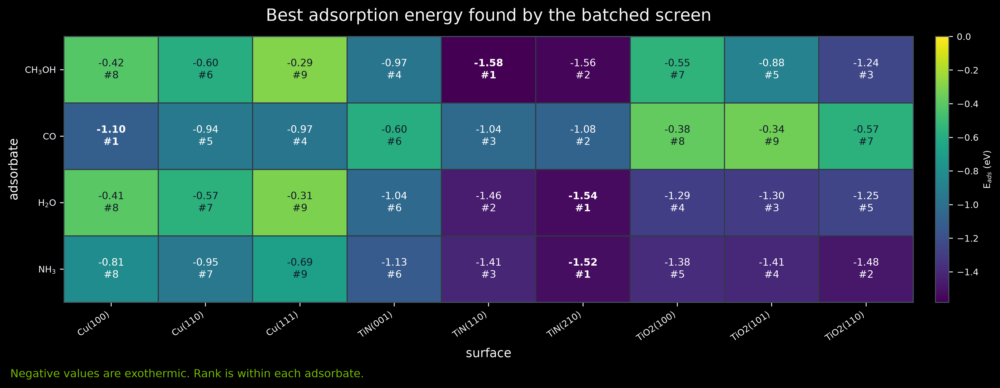

Saved: outputs/live_runs/20260617-064858/tutorial/plots/surface_screen_adsorption_heatmap.png


adsorbate,best surface in this panel,best E_ads (eV),final site,starts searched,relaxation steps,step status
CH3OH,TiN(110),-1.580933,ti-top,6,648,red
CO,Cu(100),-1.101130,hollow,6,546,red
H2O,TiN(210),-1.535505,n-top,6,648,red
NH3,TiN(210),-1.522490,ti-top,6,648,red


In [35]:
# Plot the heatmap and show the best surface found for each adsorbate.
heatmap_path = os.path.join(PLOTS_DIR, "surface_screen_adsorption_heatmap.png")
if USE_SAVED_TUTORIAL_RESULTS and not REFRESH_SAVED_RESULTS:
    if os.path.exists(heatmap_path):
        display_inline(heatmap_path)
        print(f"Using saved figure: {heatmap_path}")
    else:
        session_heatmap_path = os.path.join(
            LIVE_OUTPUT_DIR,
            "tutorial",
            "plots",
            "surface_screen_adsorption_heatmap.png",
        )
        session_heatmap_path = plot_surface_screen_heatmap(
            application_heatmap_df,
            output_path=session_heatmap_path,
            title="Best adsorption energy found by the batched screen",
        )
        display_inline(session_heatmap_path)
        print(f"Saved session figure: {session_heatmap_path}")
else:
    heatmap_path = plot_surface_screen_heatmap(
        application_heatmap_df,
        output_path=heatmap_path,
        title="Best adsorption energy found by the batched screen",
    )
    display_inline(heatmap_path)
    print(f"Saved: {heatmap_path}")

display(
    ranked_winners_df[
        [
            "adsorbate",
            "host",
            "best_E_ads_eV",
            "best_final_site",
            "n_starting_geometries",
            "best_optimizer_nsteps",
            "best_step_status",
        ]
    ]
    .rename(
        columns={
            "host": "best surface in this panel",
            "best_E_ads_eV": "best E_ads (eV)",
            "best_final_site": "final site",
            "n_starting_geometries": "starts searched",
            "best_optimizer_nsteps": "relaxation steps",
            "best_step_status": "step status",
        }
    )
    .style.hide(axis="index")
)

## Inspect the ranked final structures

The heatmap ranks energies; the structures below make the ranking inspectable. For each molecule, show the relaxed structure from the lowest-energy surface in this panel.


In [37]:
# Show the top-ranked relaxed structure for each adsorbate as interactive OVITO widgets.
from helpers.surface_screen_widgets import display_surface_screen_winner_widgets

winner_widget_result = display_surface_screen_winner_widgets(
    surface_pair_summary_df=surface_pair_summary_df,
    surface_screen_paths=SURFACE_SCREEN_PATHS,
    columns=2,
    width="460px",
    height="360px",
    header_height="92px",
    show_cell=True,
    wrap_periodic_cell=False,
)

ranked_winners_df = winner_widget_result["ranked_winners_df"]
ranked_winner_items = winner_widget_result["items"]
winner_pair_summary_path = winner_widget_result["pair_summary_path"]
winner_artifact_root = winner_widget_result["artifact_root"]

The heatmap ranks adsorption energies; these OVITO widgets show the optimizer-converged structures selected for each adsorbate. They are loaded from saved surface-screen artifacts. The displayed periodic image is adjusted only for visualization so the slab sits inside the drawn cell while the adsorbate molecule remains intact.

Loaded winner metadata from `outputs/live_runs/20260617-064858/tutorial/surface_screen_v1_mace_mpa0_full/surface_screen/tables/pair_summary.csv`.

adsorbate,surface,winning start,relaxation,atoms
CH3OH,TiN(110),CH3OH_TiN(110)_ti-top_O-down_rot0_h2.8,optimizer-converged; max force 0.012 eV/A; 648 steps,54
CO,Cu(100),CO_Cu(100)_hollow_C-down_rot0_h2.8,optimizer-converged; max force 0.015 eV/A; 546 steps,38
H2O,TiN(210),H2O_TiN(210)_bridge_H-down_rot0_h2.8,optimizer-converged; max force 0.011 eV/A; 648 steps,99
NH3,TiN(210),NH3_TiN(210)_bridge_H-down_rot0_h2.8,optimizer-converged; max force 0.017 eV/A; 648 steps,100


---

## Interpreting the adsorption screen

The heatmap is a screening result for this worked panel: after generating a local adsorption search space across surfaces, adsorbates, sites, orientations, and starting geometries, which relaxed structures bind most strongly with the selected MACE-MPA model and reference convention?

For chemistry research, this opens many possibilities to continue meaningful work where the process of interest starts when an adsorbate attaches to the surface: catalysis, mixture separation, protective film deposition, and water harvesting.

Batching changes the practical modus operandi. Instead of asking one structure for one answer, the workflow generates many plausible structures, relaxes them on the GPU, and ranks the final geometries so the researcher can see a large space all at once. This notebook only gives a glimpse of that pattern; the important point is that screening becomes an executable stage of the workflow rather than a manual preselection step.

<p style="margin:16px 0 4px; max-width:100%;">
  <img src="assets/images/adsorption_slab_1x_vs_20x_black.png" alt="Batching accelerates discovery: one slab equals 1x, batched slabs equal 20x" style="display:block; max-width:100%; height:auto; background:#000; border:1px solid #111; border-radius:8px;">
</p>

## Some limitations of this tutorial - and how model/data selection can address them

This notebook focuses on throughput screening for adsorption configurations. The limits below define which downstream questions need additional methods.

- **Activation barriers** are not computed. Thermodynamic binding is not a kinetic pathway; NEB, dimer, or string methods are required for transition states. Coverage and multi-molecule effects require separate simulations.
- **Open-shell, magnetic 3d, reducible-oxide defect, and f-electron chemistry** are excluded from these examples - MACE-MPA-0 cannot describe them. MLIPs that go beyond ground state properties could be useful for future discovery. 
- **Dispersion conventions matter.** This notebook disables D3 to match OC20Dense/OC20 reference data; in general, enabling D3 is a great inexpensive way to improve accuracy of intermolecular interactions and surface chemistry. 

## Let's stay in touch

Deepest appreciation to everyone involved, especially Wen Jie Ong, Ryan Reese, Roman Zubatyuk, Sepideh Khajehei, and the OpenHackathon team for support, feedback, and collaboration around this tutorial.

For questions, feedback, follow-up discussion, or ideas for extending the workflow, reach out to [Nikita Fedik](mailto:nfedik@nvidia.com) or [Justin Smith](mailto:jusmith@nvidia.com). We would love to hear from you and discuss how **<span style="color:#76b900; font-weight:600;">NVIDIA ALCHEMI</span>** could help accelerate your workflow.

🔗 **ALCHEMI resources:** [ALCHEMI hub](https://developer.nvidia.com/cuda/cuda-x-libraries/alchemi) · [Toolkit GitHub](https://github.com/NVIDIA/nvalchemi-toolkit) · [Toolkit-Ops GitHub](https://github.com/NVIDIA/nvalchemi-toolkit-ops)

📰 **ALCHEMI blogs:** [ALCHEMI discovery blog](https://developer.nvidia.com/blog/revolutionizing-ai-driven-material-discovery-using-nvidia-alchemi/) · [Toolkit workflows blog](https://developer.nvidia.com/blog/building-custom-atomistic-simulation-workflows-for-chemistry-and-materials-science-with-nvidia-alchemi-toolkit/) · [Toolkit-Ops blog](https://developer.nvidia.com/blog/accelerating-ai-powered-chemistry-and-materials-science-simulations-with-nvidia-alchemi-toolkit-ops/)